# Tipo de entrega × bugs, impacto e tempo de correção
**Análise exploratória e modelos preditivos com dados públicos de projetos ágeis (TAWOS)**

**Pergunta de pesquisa.** O tipo de coisa que se libera numa release (features novas, correções, tamanho, tipo de versão) influencia a quantidade de bugs gerados, o impacto e o tempo para corrigi-los?

**Hipóteses**
- **H1:** a composição e o tipo da release (major/minor/patch, % de features, tamanho, componentes tocados) estão associados à quantidade de bugs pós-release.
- **H2:** dá para prever, já na abertura do bug, em que faixa de tempo ele será corrigido, usando atributos do bug e da release afetada.

**Dados.** TAWOS (Tawosi et al., MSR 2022): 458 mil issues de 39 projetos open source em Jira, DOI 10.5522/04/21308124, licença Apache 2.0. Este notebook usa 10 projetos com versões numeradas e mistura de features e bugs (Moodle, MongoDB Server, Titanium SDK, Mule, Nexus, Titanium Studio, Mesos, MongoDB Java Driver, Hyperledger Fabric, DotNetNuke).

**Bases** (geradas por `preparar_bases.py`):
- `bases/base_releases.csv`: 1 linha por release publicada → **Modelo 2 (risco da release)**
- `bases/base_bugs.csv`: 1 linha por bug corrigido → **Modelo 1 (tempo de correção)**

O dicionário de dados está em `bases/bases_tcc.xlsx`.

**Como executar.** No computador: abra este notebook na pasta do projeto e rode todas as células (≈ 4 min). No **Google Colab**: use o botão "Open in Colab" do README do repositório; a célula abaixo baixa o repositório e instala as bibliotecas automaticamente.

In [1]:
# Preparação para o Google Colab (no computador local esta célula não faz nada)
import os, sys, subprocess
REPO = "https://github.com/alineosilveira/tcc-governanca-operacional-ml.git"
if "google.colab" in sys.modules and not os.path.exists("bases"):
    subprocess.run(["git", "clone", "-q", REPO, "repo"], check=True)
    os.chdir("repo")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost", "shap", "statsmodels", "openpyxl"], check=True)
    print("Repositório baixado e bibliotecas instaladas.")

In [2]:
# Se faltar alguma biblioteca, descomente a linha abaixo:
# %pip install pandas numpy matplotlib seaborn scipy scikit-learn statsmodels xgboost shap openpyxl

import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
os.makedirs("figuras", exist_ok=True)
RANDOM_STATE = 42

def salvar(nome):
    plt.tight_layout()
    plt.savefig(f"figuras/{nome}.png", bbox_inches="tight")
    plt.show()

rel = pd.read_csv("bases/base_releases.csv", parse_dates=["Release_Date"])
bugs = pd.read_csv("bases/base_bugs.csv", parse_dates=["Creation_Date", "Resolution_Date"])
ORDEM_TIPO = ["major", "minor", "patch", "pre-release"]
print(f"Releases: {len(rel):,} | Bugs corrigidos: {len(bugs):,} | Projetos: {rel.Project_Key.nunique()}")

Releases: 1,249 | Bugs corrigidos: 55,649 | Projetos: 10


## 1. Visão geral dos dados

In [3]:
resumo = pd.DataFrame({
    "releases": rel.groupby("Project_Key").size(),
    "periodo_releases": rel.groupby("Project_Key").Release_Date.agg(lambda s: f"{s.min():%Y}–{s.max():%Y}"),
    "bugs_corrigidos": bugs.groupby("Project_Key").size(),
    "mediana_bugs_pos_release": rel.groupby("Project_Key").Bugs_Pos_Release.median(),
    "mediana_dias_correcao": bugs.groupby("Project_Key").Dias_Para_Corrigir.median().round(1),
}).sort_values("releases", ascending=False)
resumo

,releases,periodo_releases,bugs_corrigidos,mediana_bugs_pos_release,mediana_dias_correcao
Project_Key,,,,,
SERVER,359,2009–2020,11919,14.0,7.0
MDL,243,2005–2020,18441,50.0,16.4
TIMOB,138,2009–2020,8369,13.0,12.3
MULE,137,2004–2019,3622,11.0,11.0
NEXUS,120,2008–2020,3192,18.0,12.9
JAVA,81,2009–2020,563,4.0,5.7
MESOS,70,2012–2019,2756,6.0,16.0
TISTUD,49,2011–2019,1980,16.0,7.9
FAB,30,2016–2020,2596,15.5,7.5


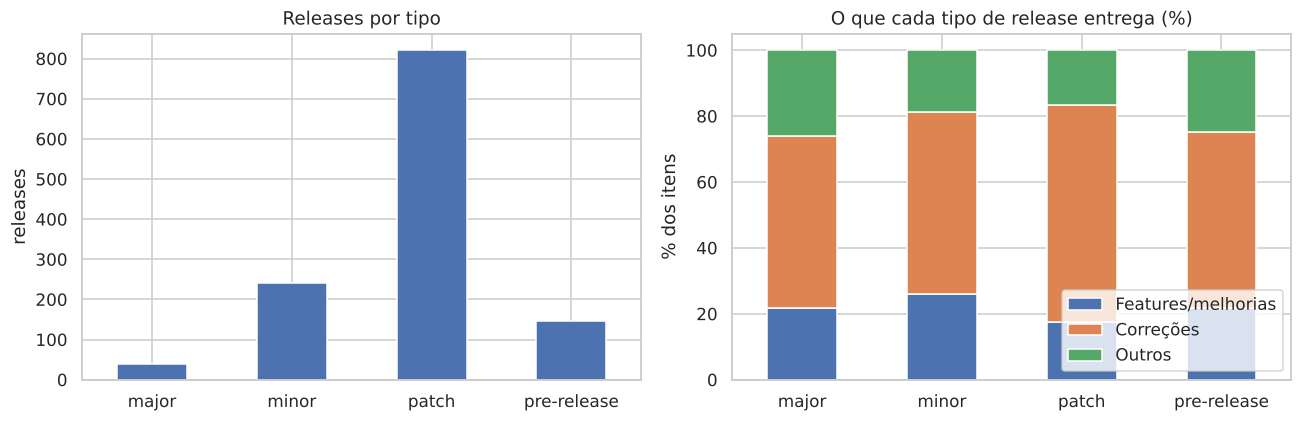

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rel.Tipo_Release.value_counts().reindex(ORDEM_TIPO).plot.bar(ax=ax[0], color="#4C72B0", rot=0)
ax[0].set_title("Releases por tipo"); ax[0].set_xlabel(""); ax[0].set_ylabel("releases")
comp = rel.groupby("Tipo_Release")[["Qtd_Features", "Qtd_Correcoes", "Qtd_Outros"]].sum().reindex(ORDEM_TIPO)
(comp.div(comp.sum(axis=1), axis=0) * 100).plot.bar(stacked=True, ax=ax[1], rot=0)
ax[1].set_title("O que cada tipo de release entrega (%)"); ax[1].set_xlabel(""); ax[1].set_ylabel("% dos itens")
ax[1].legend(["Features/melhorias", "Correções", "Outros"], loc="lower right")
salvar("01_tipos_release")

## 2. Análises tradicionais: release × bugs pós-release

**Bugs pós-release** são os bugs abertos até 180 dias após a publicação e atribuídos à versão afetada mais antiga, ou seja, à release que primeiro "carregou" o defeito. Cada bug conta uma única vez. Como proxy de **impacto em cliente**, usamos os bugs de prioridade alta ou bloqueante.

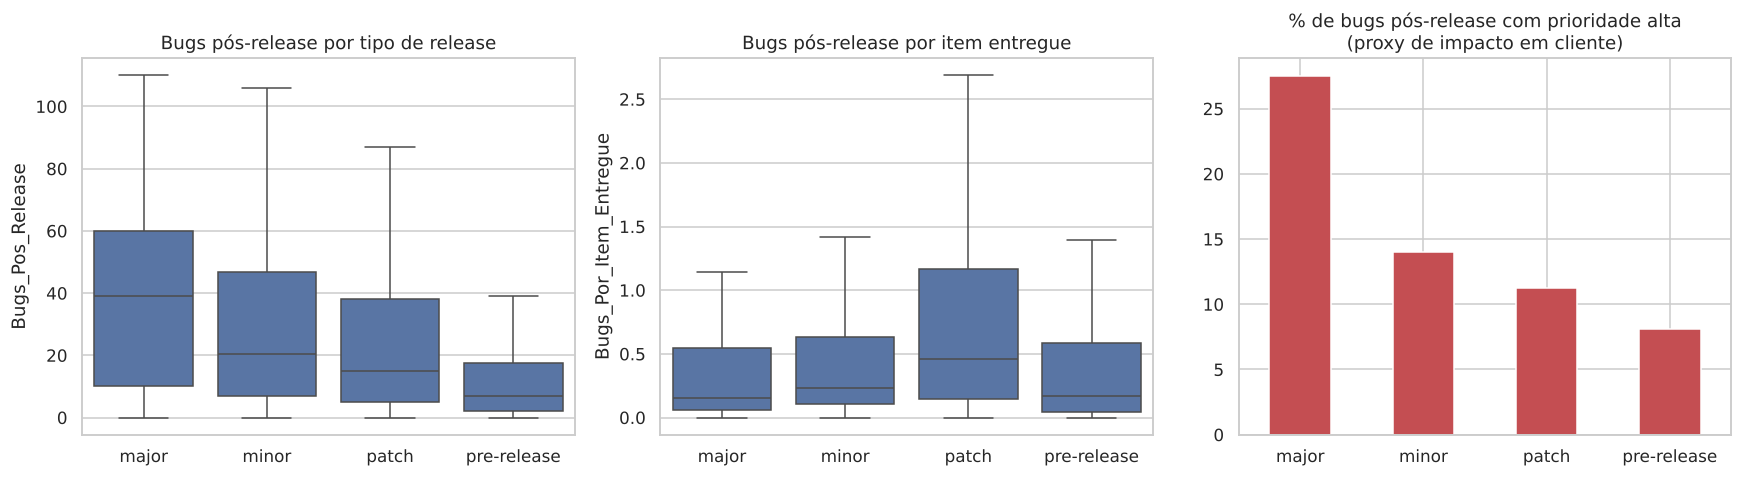

Mediana por tipo de release:


,Qtd_Itens,Pct_Features,Bugs_Pos_Release,Bugs_Pos_Release_Alta,Bugs_Por_Item_Entregue,Dias_Medianos_Correcao_Pos_Release
Tipo_Release,,,,,,
major,132.0,0.29,39.0,7.0,0.16,13.59
minor,64.0,0.28,20.5,1.0,0.23,20.24
patch,33.0,0.14,15.0,0.0,0.46,19.39
pre-release,36.0,0.20,7.0,0.0,0.17,7.22


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=rel, x="Tipo_Release", y="Bugs_Pos_Release", order=ORDEM_TIPO, ax=ax[0], showfliers=False)
ax[0].set_title("Bugs pós-release por tipo de release"); ax[0].set_xlabel("")
sns.boxplot(data=rel, x="Tipo_Release", y="Bugs_Por_Item_Entregue", order=ORDEM_TIPO, ax=ax[1], showfliers=False)
ax[1].set_title("Bugs pós-release por item entregue"); ax[1].set_xlabel("")
alta = rel.groupby("Tipo_Release")[["Bugs_Pos_Release_Alta", "Bugs_Pos_Release"]].sum().reindex(ORDEM_TIPO)
(alta.Bugs_Pos_Release_Alta / alta.Bugs_Pos_Release * 100).plot.bar(ax=ax[2], color="#C44E52", rot=0)
ax[2].set_title("% de bugs pós-release com prioridade alta\n(proxy de impacto em cliente)"); ax[2].set_xlabel("")
salvar("02_bugs_por_tipo_release")

print("Mediana por tipo de release:")
display(rel.groupby("Tipo_Release")[["Qtd_Itens", "Pct_Features", "Bugs_Pos_Release", "Bugs_Pos_Release_Alta",
                                     "Bugs_Por_Item_Entregue", "Dias_Medianos_Correcao_Pos_Release"]]
        .median().reindex(ORDEM_TIPO).round(2))

### 2.1 Teste estatístico: o tipo de release muda a quantidade de bugs?
As distribuições são assimétricas, então usamos testes não paramétricos: Kruskal-Wallis para todos os grupos e Mann-Whitney par a par, com correção de Bonferroni.

In [6]:
from itertools import combinations

def kruskal_e_pares(df, grupo, valor, ordem):
    grupos = [df.loc[df[grupo] == g, valor].dropna() for g in ordem]
    h, p = stats.kruskal(*grupos)
    n = sum(len(g) for g in grupos)
    eps2 = (h - len(grupos) + 1) / (n - len(grupos))   # tamanho de efeito (epsilon²)
    print(f"Kruskal-Wallis ({valor}): H = {h:.1f}, p = {p:.2e}, epsilon² = {eps2:.3f}")
    linhas = []
    pares = list(combinations(ordem, 2))
    for a, b in pares:
        x, y = df.loc[df[grupo] == a, valor].dropna(), df.loc[df[grupo] == b, valor].dropna()
        u, pu = stats.mannwhitneyu(x, y, alternative="two-sided")
        linhas.append((a, b, x.median(), y.median(), min(pu * len(pares), 1.0)))
    return pd.DataFrame(linhas, columns=["grupo_A", "grupo_B", "mediana_A", "mediana_B", "p_bonferroni"]).round(4)

display(kruskal_e_pares(rel, "Tipo_Release", "Bugs_Pos_Release", ORDEM_TIPO))
display(kruskal_e_pares(rel, "Tipo_Release", "Bugs_Por_Item_Entregue", ORDEM_TIPO))

Kruskal-Wallis (Bugs_Pos_Release): H = 50.0, p = 7.92e-11, epsilon² = 0.038


,grupo_A,grupo_B,mediana_A,mediana_B,p_bonferroni
0,major,minor,39.0,20.5,1.0000
1,major,patch,39.0,15.0,0.1283
2,major,pre-release,39.0,7.0,0.0000
3,minor,patch,20.5,15.0,0.0709
4,minor,pre-release,20.5,7.0,0.0000
5,patch,pre-release,15.0,7.0,0.0000


Kruskal-Wallis (Bugs_Por_Item_Entregue): H = 50.6, p = 5.97e-11, epsilon² = 0.038


,grupo_A,grupo_B,mediana_A,mediana_B,p_bonferroni
0,major,minor,0.1567,0.2323,0.9378
1,major,patch,0.1567,0.4615,0.0163
2,major,pre-release,0.1567,0.1690,1.0000
3,minor,patch,0.2323,0.4615,0.0001
4,minor,pre-release,0.2323,0.1690,0.0895
5,patch,pre-release,0.4615,0.1690,0.0000


### 2.2 Composição e tamanho da release × bugs (correlação de Spearman)

,variavel,rho_spearman,p_valor
2,Qtd_Correcoes,0.5492,0.0000
4,Qtd_Componentes_Tocados,0.5345,0.0000
0,Qtd_Itens,0.5121,0.0000
1,Qtd_Features,0.3789,0.0000
5,Qtd_Itens_Alta_Prioridade,0.2472,0.0000
6,Dias_Desde_Release_Anterior,0.0756,0.0077
3,Pct_Features,-0.0242,0.3935


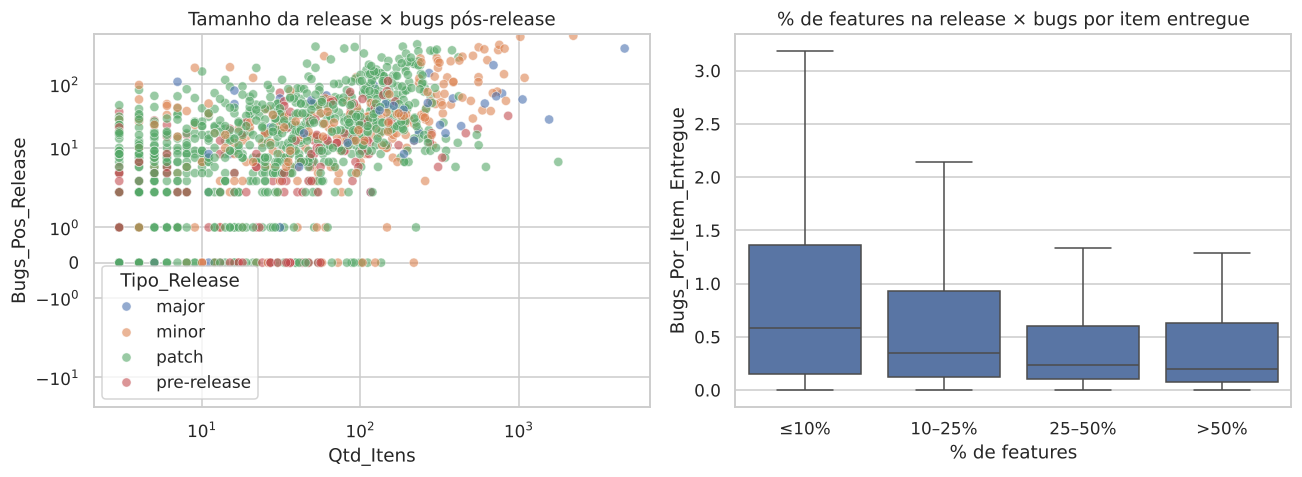

In [7]:
vars_rel = ["Qtd_Itens", "Qtd_Features", "Qtd_Correcoes", "Pct_Features", "Qtd_Componentes_Tocados",
            "Qtd_Itens_Alta_Prioridade", "Dias_Desde_Release_Anterior"]
corr = pd.DataFrame([(v, *stats.spearmanr(rel[v], rel.Bugs_Pos_Release, nan_policy="omit")) for v in vars_rel],
                    columns=["variavel", "rho_spearman", "p_valor"]).sort_values("rho_spearman", ascending=False)
display(corr.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=rel, x="Qtd_Itens", y="Bugs_Pos_Release", hue="Tipo_Release", hue_order=ORDEM_TIPO, alpha=.6, ax=ax[0])
ax[0].set(xscale="log", yscale="symlog", title="Tamanho da release × bugs pós-release")
rel["Faixa_Pct_Features"] = pd.cut(rel.Pct_Features, [-.01, .1, .25, .5, 1], labels=["≤10%", "10–25%", "25–50%", ">50%"])
sns.boxplot(data=rel, x="Faixa_Pct_Features", y="Bugs_Por_Item_Entregue", ax=ax[1], showfliers=False)
ax[1].set_title("% de features na release × bugs por item entregue"); ax[1].set_xlabel("% de features")
salvar("03_composicao_release")

### 2.3 Modelo estatístico explicativo (Binomial Negativa)
Controla ao mesmo tempo o tamanho da release, o mix e o projeto, que é o efeito fixo. O **exp(coef)** é a razão de taxas: por exemplo, 1,30 significa 30% mais bugs pós-release, mantendo o resto constante. É a evidência inferencial para **H1**.

In [8]:
import statsmodels.formula.api as smf

d = rel.copy()
d["log_itens"] = np.log1p(d.Qtd_Itens)
d["log_componentes"] = np.log1p(d.Qtd_Componentes_Tocados)
d["log_dias_ant"] = np.log1p(d.Dias_Desde_Release_Anterior.fillna(d.Dias_Desde_Release_Anterior.median()))
d["pct_features_10pp"] = d.Pct_Features * 10
d["pct_alta"] = d.Qtd_Itens_Alta_Prioridade / d.Qtd_Itens
nb = smf.negativebinomial(
    "Bugs_Pos_Release ~ C(Tipo_Release, Treatment('minor')) + pct_features_10pp + pct_alta"
    " + log_itens + log_componentes + log_dias_ant + C(Project_Key)", data=d).fit(disp=0, maxiter=200)
tab = pd.DataFrame({"razao_de_taxas": np.exp(nb.params), "IC95_inf": np.exp(nb.conf_int()[0]),
                    "IC95_sup": np.exp(nb.conf_int()[1]), "p_valor": nb.pvalues})
tab = tab[~tab.index.str.startswith("C(Project_Key)")].drop(index=["Intercept", "alpha"], errors="ignore")
print(f"Pseudo-R² (McFadden): {nb.prsquared:.3f}   n = {int(nb.nobs)}")
tab.round(3)

Pseudo-R² (McFadden): 0.069   n = 1249


,razao_de_taxas,IC95_inf,IC95_sup,p_valor
"C(Tipo_Release, Treatment('minor'))[T.major]",1.071,0.745,1.540,0.711
"C(Tipo_Release, Treatment('minor'))[T.patch]",0.688,0.576,0.822,0.000
"C(Tipo_Release, Treatment('minor'))[T.pre-release]",0.439,0.342,0.564,0.000
pct_features_10pp,0.989,0.943,1.038,0.649
pct_alta,3.436,2.166,5.450,0.000
log_itens,1.271,1.166,1.386,0.000
log_componentes,1.240,1.073,1.433,0.004
log_dias_ant,1.130,1.074,1.188,0.000


## 3. Análises tradicionais: tempo de correção de bugs
`Dias_Para_Corrigir` é o tempo entre a abertura e a resolução do bug, ou seja, o tempo que o cliente espera.

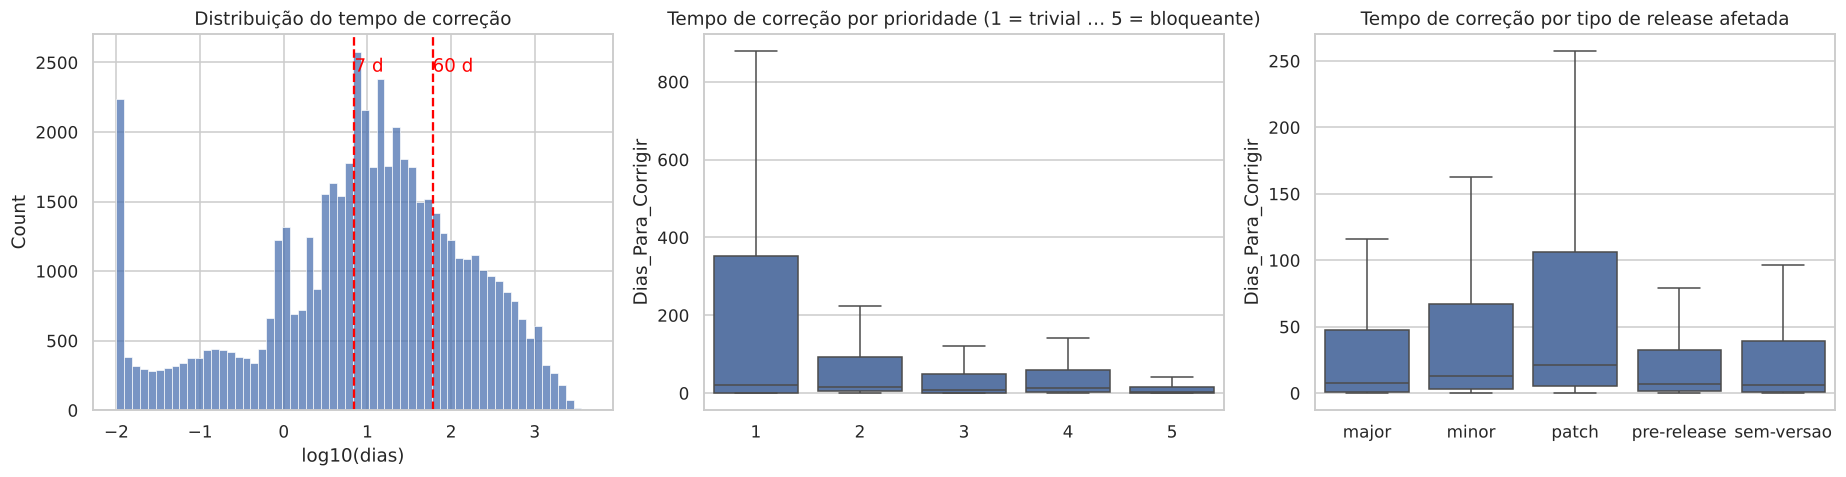

Faixa_Correcao,8_a_60_dias,ate_7_dias,mais_de_60_dias
Tipo_Release_Afetada,,,
major,28.9,49.0,22.1
minor,37.4,36.3,26.3
patch,37.6,29.9,32.4
pre-release,33.1,49.4,17.5
sem-versao,27.8,51.9,20.3


Kruskal-Wallis (Dias_Para_Corrigir): H = 2295.1, p = 0.00e+00, epsilon² = 0.041


,grupo_A,grupo_B,mediana_A,mediana_B,p_bonferroni
0,major,minor,7.3720,12.9938,0.0
1,major,patch,7.3720,20.9104,0.0
2,major,pre-release,7.3720,7.0631,1.0
3,major,sem-versao,7.3720,6.1898,0.0
4,minor,patch,12.9938,20.9104,0.0
5,minor,pre-release,12.9938,7.0631,0.0
6,minor,sem-versao,12.9938,6.1898,0.0
7,patch,pre-release,20.9104,7.0631,0.0
8,patch,sem-versao,20.9104,6.1898,0.0
9,pre-release,sem-versao,7.0631,6.1898,0.0


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(np.log10(bugs.Dias_Para_Corrigir + 0.01), bins=60, ax=ax[0])
ax[0].set_title("Distribuição do tempo de correção"); ax[0].set_xlabel("log10(dias)")
for x, lbl in [(np.log10(7), "7 d"), (np.log10(60), "60 d")]:
    ax[0].axvline(x, color="red", ls="--"); ax[0].text(x, ax[0].get_ylim()[1]*.9, lbl, color="red")
sns.boxplot(data=bugs, x="Prioridade_Nivel", y="Dias_Para_Corrigir", ax=ax[1], showfliers=False)
ax[1].set_title("Tempo de correção por prioridade (1 = trivial … 5 = bloqueante)"); ax[1].set_xlabel("")
ordem_af = ORDEM_TIPO + ["sem-versao"]
sns.boxplot(data=bugs, x="Tipo_Release_Afetada", y="Dias_Para_Corrigir", order=ordem_af, ax=ax[2], showfliers=False)
ax[2].set_title("Tempo de correção por tipo de release afetada"); ax[2].set_xlabel("")
salvar("04_tempo_correcao")

display(pd.crosstab(bugs.Tipo_Release_Afetada, bugs.Faixa_Correcao, normalize="index").reindex(ordem_af).round(3) * 100)
display(kruskal_e_pares(bugs, "Tipo_Release_Afetada", "Dias_Para_Corrigir", ordem_af))

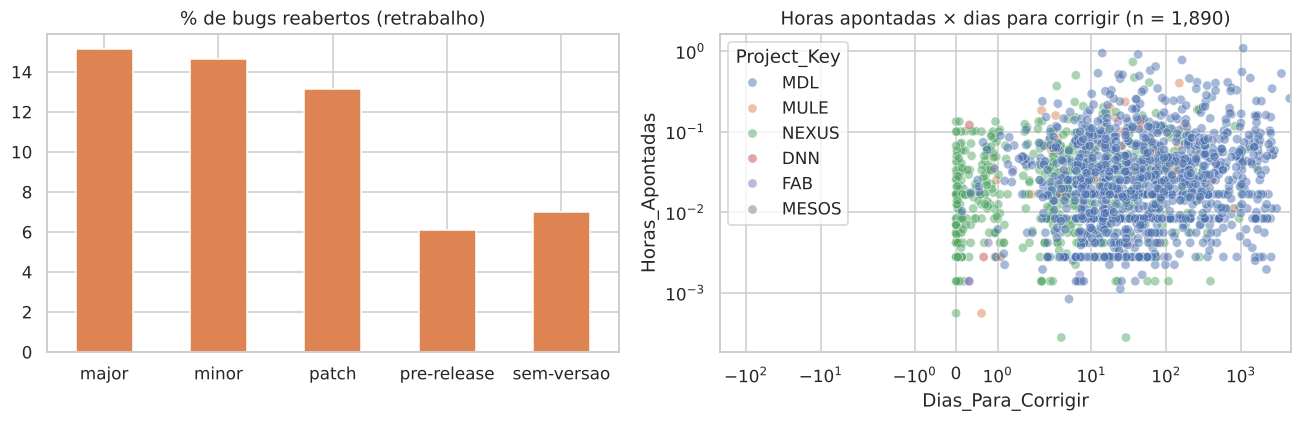

Horas apontadas preenchidas em 3.4% dos bugs (sobretudo MDL e NEXUS).
Spearman horas × dias: rho = 0.17 (p = 7.9e-14). O prazo de calendário não equivale ao esforço.


In [10]:
# Reaberturas (retrabalho) e horas apontadas
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(bugs.groupby("Tipo_Release_Afetada").Qtd_Reaberturas.apply(lambda s: (s > 0).mean() * 100)
     .reindex(ordem_af).plot.bar(ax=ax[0], color="#DD8452", rot=0))
ax[0].set_title("% de bugs reabertos (retrabalho)"); ax[0].set_xlabel("")
h = bugs.dropna(subset=["Horas_Apontadas"]).query("Horas_Apontadas > 0")
sns.scatterplot(data=h, x="Dias_Para_Corrigir", y="Horas_Apontadas", hue="Project_Key", alpha=.5, ax=ax[1])
ax[1].set(xscale="symlog", yscale="log", title=f"Horas apontadas × dias para corrigir (n = {len(h):,})")
salvar("05_reaberturas_horas")
rho, p = stats.spearmanr(h.Dias_Para_Corrigir, h.Horas_Apontadas)
print(f"Horas apontadas preenchidas em {bugs.Horas_Apontadas.notna().mean():.1%} dos bugs (sobretudo MDL e NEXUS).")
print(f"Spearman horas × dias: rho = {rho:.2f} (p = {p:.1e}). O prazo de calendário não equivale ao esforço.")

## 4. Modelo 1: prever a faixa de tempo de correção de um bug (H2)

- **Alvo:** `Faixa_Correcao`, com três classes: até 7 dias, de 8 a 60 dias e mais de 60 dias.
- **Features:** apenas o que se sabe **no dia em que o bug é aberto**, como prioridade inicial, texto, componentes, release afetada, carga do time e experiência de quem reportou.
- **Divisão temporal:** o treino usa bugs abertos até 30/06/2016 e o teste usa bugs abertos depois, simulando o uso real (aprender com o passado e prever o futuro).
- **Modelos comparados:** baseline (classe mais frequente), Regressão Logística, Random Forest e XGBoost.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, f1_score, balanced_accuracy_score, roc_auc_score,
                             ConfusionMatrixDisplay, accuracy_score)
from xgboost import XGBClassifier

CAT_B = ["Project_Key", "Tipo_Release_Afetada"]
NUM_B = ["Prioridade_Nivel", "Tamanho_Titulo", "Tamanho_Descricao", "Tamanho_Codigo_Descricao",
         "Tem_Codigo_Na_Descricao", "Qtd_Componentes", "Qtd_Versoes_Afetadas", "Dias_Desde_Release_Afetada",
         "Itens_Release_Afetada", "Pct_Features_Release_Afetada", "Bugs_Abertos_No_Projeto",
         "Experiencia_Reporter", "Mes_Abertura", "Dia_Semana_Abertura", "Tem_Story_Point"]
CLASSES = ["ate_7_dias", "8_a_60_dias", "mais_de_60_dias"]

corte_b = pd.Timestamp("2016-07-01")
tr_b, te_b = bugs[bugs.Creation_Date < corte_b], bugs[bugs.Creation_Date >= corte_b]
Xtr_b, Xte_b = tr_b[CAT_B + NUM_B], te_b[CAT_B + NUM_B]
ytr_b = tr_b.Faixa_Correcao.map({c: i for i, c in enumerate(CLASSES)})
yte_b = te_b.Faixa_Correcao.map({c: i for i, c in enumerate(CLASSES)})
print(f"Treino: {len(tr_b):,} bugs | Teste: {len(te_b):,} bugs")
display(pd.DataFrame({"treino": ytr_b.value_counts(normalize=True).sort_index().values,
                      "teste": yte_b.value_counts(normalize=True).sort_index().values}, index=CLASSES).round(3))

def preproc(cat, num, escalar):
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=True)),
                 ("log", FunctionTransformer(lambda X: np.sign(X) * np.log1p(np.abs(X)), feature_names_out="one-to-one"))]
    if escalar:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
                              ("num", Pipeline(num_steps), num)], verbose_feature_names_out=False)

modelos_b = {
    "Baseline (classe mais frequente)": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8,
                             colsample_bytree=0.8, eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=-1),
}

def avaliar(modelos, Xtr, ytr, Xte, yte, cat, num, multiclasse):
    res, fitted = [], {}
    for nome, m in modelos.items():
        pipe = Pipeline([("prep", preproc(cat, num, escalar=nome.startswith("Regressão"))), ("modelo", m)])
        if nome == "XGBoost" and multiclasse:   # balanceia classes via peso de amostra
            w = ytr.map(1 / ytr.value_counts(normalize=True)).values
            pipe.fit(Xtr, ytr, modelo__sample_weight=w)
        else:
            pipe.fit(Xtr, ytr)
        pred, proba = pipe.predict(Xte), pipe.predict_proba(Xte)
        auc = roc_auc_score(yte, proba, multi_class="ovr") if multiclasse else roc_auc_score(yte, proba[:, 1])
        res.append({"modelo": nome, "acuracia": accuracy_score(yte, pred),
                    "acuracia_balanceada": balanced_accuracy_score(yte, pred),
                    "F1_macro": f1_score(yte, pred, average="macro"), "AUC": auc})
        fitted[nome] = pipe
    return pd.DataFrame(res).set_index("modelo").round(3), fitted

res_b, fit_b = avaliar(modelos_b, Xtr_b, ytr_b, Xte_b, yte_b, CAT_B, NUM_B, multiclasse=True)
res_b

Treino: 40,089 bugs | Teste: 15,560 bugs


,treino,teste
ate_7_dias,0.411,0.394
8_a_60_dias,0.316,0.392
mais_de_60_dias,0.273,0.214


,acuracia,acuracia_balanceada,F1_macro,AUC
modelo,,,,
Baseline (classe mais frequente),0.394,0.333,0.188,0.500
Regressão Logística,0.449,0.440,0.433,0.618
Random Forest,0.474,0.457,0.451,0.654
XGBoost,0.473,0.461,0.450,0.649


Melhor modelo (F1 macro): Random Forest



                 precision    recall  f1-score   support

     ate_7_dias      0.509     0.639     0.567      6128
    8_a_60_dias      0.510     0.368     0.428      6098
mais_de_60_dias      0.350     0.365     0.357      3334

       accuracy                          0.474     15560
      macro avg      0.457     0.457     0.451     15560
   weighted avg      0.476     0.474     0.467     15560



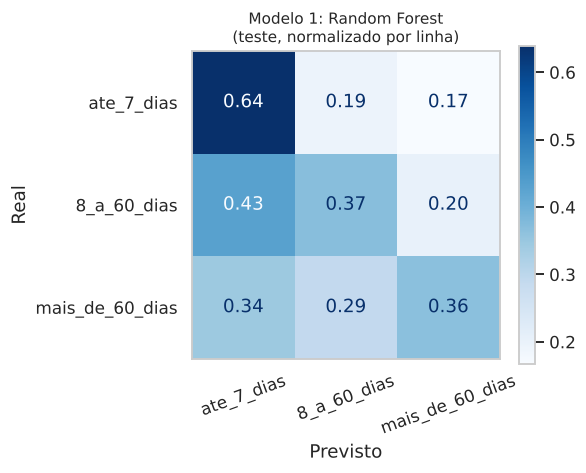

In [12]:
melhor_b = res_b.drop(index="Baseline (classe mais frequente)").F1_macro.idxmax()
print(f"Melhor modelo (F1 macro): {melhor_b}\n")
pred = fit_b[melhor_b].predict(Xte_b)
print(classification_report(yte_b, pred, target_names=CLASSES, digits=3))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(yte_b, pred, display_labels=CLASSES, normalize="true",
                                        values_format=".2f", cmap="Blues", ax=ax, xticks_rotation=20)
ax.set_title(f"Modelo 1: {melhor_b}\n(teste, normalizado por linha)", fontsize=10); ax.grid(False); ax.set(xlabel="Previsto", ylabel="Real")
salvar("06_modelo1_matriz_confusao")

### 4.1 Validação cruzada temporal (robustez)
Repete o treino e teste em 4 janelas no tempo (`TimeSeriesSplit`) para mostrar que o resultado não depende de um único corte.

In [13]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate
X_all, y_all = bugs[CAT_B + NUM_B], bugs.Faixa_Correcao.map({c: i for i, c in enumerate(CLASSES)})
cv_res = {}
for nome in ["Regressão Logística", "XGBoost"]:
    pipe = Pipeline([("prep", preproc(CAT_B, NUM_B, escalar=nome.startswith("Regressão"))), ("modelo", modelos_b[nome])])
    s = cross_validate(pipe, X_all, y_all, cv=TimeSeriesSplit(n_splits=4), scoring=["f1_macro", "balanced_accuracy"])
    cv_res[nome] = {"F1_macro (média ± dp)": f"{s['test_f1_macro'].mean():.3f} ± {s['test_f1_macro'].std():.3f}",
                    "Acurácia bal. (média ± dp)": f"{s['test_balanced_accuracy'].mean():.3f} ± {s['test_balanced_accuracy'].std():.3f}"}
pd.DataFrame(cv_res).T

,F1_macro (média ± dp),Acurácia bal. (média ± dp)
Regressão Logística,0.393 ± 0.029,0.409 ± 0.017
XGBoost,0.432 ± 0.025,0.453 ± 0.009


### 4.2 Explicabilidade (SHAP): o que mais pesa no tempo de correção?

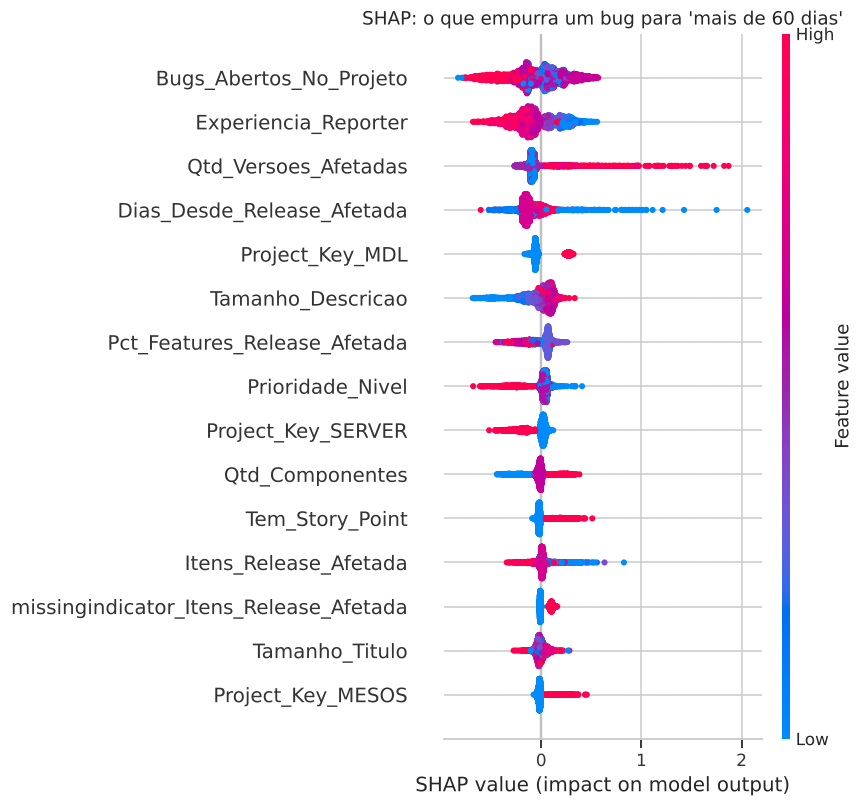

In [14]:
import shap
xgb_pipe = fit_b["XGBoost"]
Xs = xgb_pipe.named_steps["prep"].transform(Xte_b.sample(3000, random_state=RANDOM_STATE))
nomes = xgb_pipe.named_steps["prep"].get_feature_names_out()
sv = shap.TreeExplainer(xgb_pipe.named_steps["modelo"]).shap_values(Xs)
sv_longa = sv[:, :, 2] if np.ndim(sv) == 3 else sv[2]       # classe "mais_de_60_dias"
shap.summary_plot(sv_longa, Xs, feature_names=nomes, max_display=15, show=False)
plt.title("SHAP: o que empurra um bug para 'mais de 60 dias'")
salvar("07_modelo1_shap")

## 5. Modelo 2: prever se uma release será de alto risco (H1)

- **Alvo:** `Alto_Risco = 1` quando os bugs pós-release ficam acima da mediana do próprio projeto. A comparação dentro do projeto neutraliza o porte de cada um.
- **Features:** o que se sabe **no dia da publicação**: tipo da release, mix, tamanho, componentes, prioridade dos itens e intervalo desde a release anterior.
- **Divisão temporal:** o treino usa releases até 31/12/2016 e o teste usa releases a partir de 2017.
- Como a amostra é menor (cerca de 1.250 releases), também usamos modelos mais simples e regularizados.

In [15]:
CAT_R = ["Project_Key", "Tipo_Release"]
NUM_R = ["Qtd_Itens", "Qtd_Features", "Qtd_Correcoes", "Qtd_Outros", "Pct_Features", "Pct_Correcoes",
         "Qtd_Itens_Alta_Prioridade", "Story_Points_Total", "Qtd_Componentes_Tocados",
         "Tamanho_Medio_Descricao", "Dias_Desde_Release_Anterior"]
corte_r = pd.Timestamp("2017-01-01")
tr_r, te_r = rel[rel.Release_Date < corte_r], rel[rel.Release_Date >= corte_r]
print(f"Treino: {len(tr_r)} releases | Teste: {len(te_r)} releases | % alto risco no teste: {te_r.Alto_Risco.mean():.1%}")

modelos_r = {
    "Baseline (classe mais frequente)": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": LogisticRegression(max_iter=2000, C=0.5, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_depth=8,
                                            class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8,
                             colsample_bytree=0.8, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
}
res_r, fit_r = avaliar(modelos_r, tr_r[CAT_R + NUM_R], tr_r.Alto_Risco, te_r[CAT_R + NUM_R], te_r.Alto_Risco,
                       CAT_R, NUM_R, multiclasse=False)
res_r

Treino: 831 releases | Teste: 418 releases | % alto risco no teste: 35.2%


,acuracia,acuracia_balanceada,F1_macro,AUC
modelo,,,,
Baseline (classe mais frequente),0.352,0.500,0.260,0.500
Regressão Logística,0.629,0.642,0.621,0.713
Random Forest,0.660,0.666,0.649,0.715
XGBoost,0.624,0.648,0.620,0.703


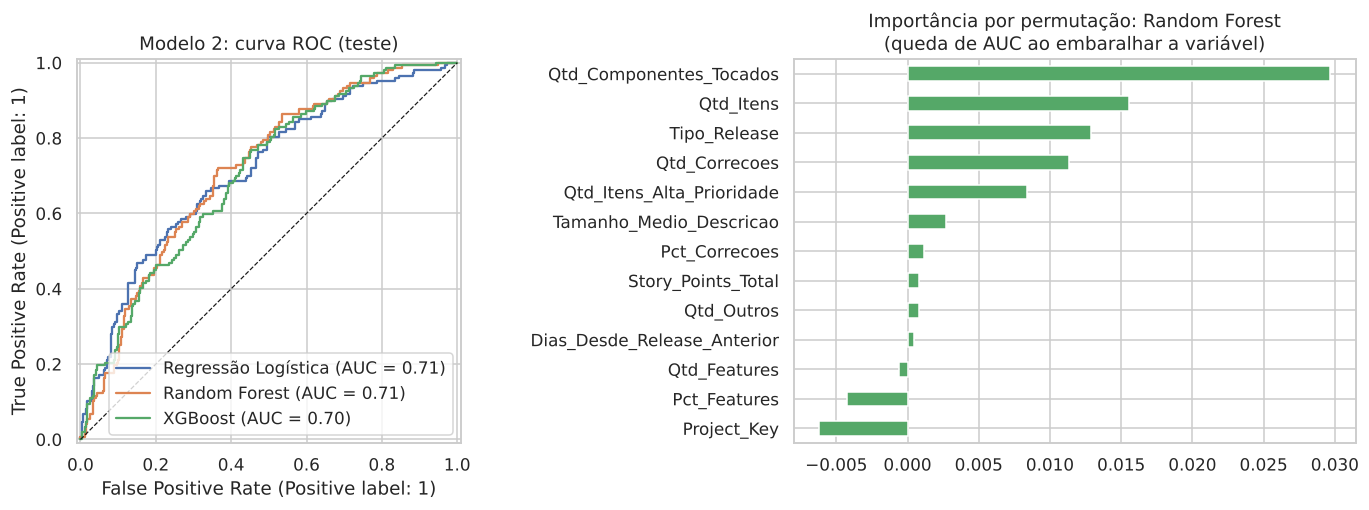

Melhor modelo (AUC): Random Forest
              precision    recall  f1-score   support

 baixo risco      0.792     0.646     0.711       271
  alto risco      0.513     0.687     0.587       147

    accuracy                          0.660       418
   macro avg      0.652     0.666     0.649       418
weighted avg      0.694     0.660     0.668       418



In [16]:
from sklearn.metrics import RocCurveDisplay
from sklearn.inspection import permutation_importance

melhor_r = res_r.drop(index="Baseline (classe mais frequente)").AUC.idxmax()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for nome in ["Regressão Logística", "Random Forest", "XGBoost"]:
    RocCurveDisplay.from_estimator(fit_r[nome], te_r[CAT_R + NUM_R], te_r.Alto_Risco, ax=ax[0], name=nome)
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_title("Modelo 2: curva ROC (teste)")
pi = permutation_importance(fit_r[melhor_r], te_r[CAT_R + NUM_R], te_r.Alto_Risco, scoring="roc_auc",
                            n_repeats=30, random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=CAT_R + NUM_R).sort_values()
imp.plot.barh(ax=ax[1], color="#55A868")
ax[1].set_title(f"Importância por permutação: {melhor_r}\n(queda de AUC ao embaralhar a variável)")
salvar("08_modelo2_roc_importancia")
print(f"Melhor modelo (AUC): {melhor_r}")
print(classification_report(te_r.Alto_Risco, fit_r[melhor_r].predict(te_r[CAT_R + NUM_R]),
                            target_names=["baixo risco", "alto risco"], digits=3))

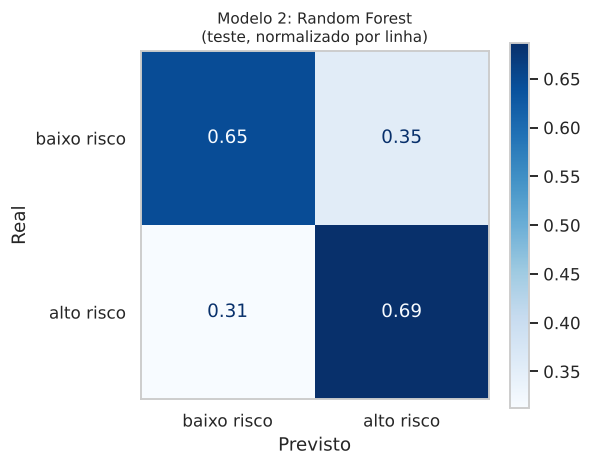

In [17]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_estimator(fit_r[melhor_r], te_r[CAT_R + NUM_R], te_r.Alto_Risco, display_labels=["baixo risco", "alto risco"], normalize="true",
                                      values_format=".2f", cmap="Blues", ax=ax)
ax.set_title("Modelo 2: " + melhor_r + "\n(teste, normalizado por linha)", fontsize=10); ax.grid(False); ax.set(xlabel="Previsto", ylabel="Real")
salvar("08b_modelo2_matriz_confusao")

# 6. Perguntas complementares
As perguntas abaixo usam a mesma base e se conectam às rotinas de PMO do trabalho: previsto × realizado nos sprints, capacidade, risco de pessoa-chave, retrabalho e impacto em cliente.

In [18]:
from sklearn.metrics import average_precision_score, precision_recall_curve, PrecisionRecallDisplay

def avaliar_bin(Xtr, ytr, Xte, yte, cat, num):
    peso = (1 - ytr.mean()) / ytr.mean()
    modelos = {
        "Baseline (classe mais frequente)": DummyClassifier(strategy="most_frequent"),
        "Regressão Logística": LogisticRegression(max_iter=3000, class_weight="balanced"),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight="balanced",
                                                n_jobs=-1, random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                                 scale_pos_weight=peso, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
    }
    res, fitted = [], {}
    for nome, m in modelos.items():
        pipe = Pipeline([("prep", preproc(cat, num, escalar=nome.startswith("Regressão"))), ("modelo", m)]).fit(Xtr, ytr)
        proba, pred = pipe.predict_proba(Xte)[:, 1], pipe.predict(Xte)
        res.append({"modelo": nome, "AUC": roc_auc_score(yte, proba),
                    "PR_AUC (precisão média)": average_precision_score(yte, proba),
                    "taxa_base_positivos": yte.mean(),
                    "recall_positivos": (pred[yte.values == 1] == 1).mean(),
                    "precisao_positivos": yte.values[pred == 1].mean() if (pred == 1).any() else 0,
                    "F1_macro": f1_score(yte, pred, average="macro")})
        fitted[nome] = pipe
    return pd.DataFrame(res).set_index("modelo").round(3), fitted

## 6.1 Previsto × realizado nos sprints (P1)
A partir do histórico do campo *Sprint* de cada item, reconstruímos para cada sprint fechado:
- o que foi **planejado**: itens no sprint até 1 dia após o início;
- o que foi **adicionado** ou **removido** durante o sprint;
- o que foi **concluído** e o que **escorregou** para o sprint seguinte (*spillover*).

São 8 projetos com sprints registrados. SERVER e DNN usam sprints, mas a base não traz as datas deles.

In [19]:
spr = pd.read_csv("bases/base_sprints.csv", parse_dates=["Start_Date", "Complete_Date"])
its = pd.read_csv("bases/base_itens_sprint.csv", parse_dates=["Start_Date"])
print(f"{len(spr):,} sprints | {len(its):,} itens planejados")
tab = spr.groupby("Project_Key").agg(
    sprints=("Sprint_ID", "size"),
    duracao_mediana_dias=("Duracao_Dias", "median"),
    itens_planejados_mediana=("Itens_Planejados", "median"),
    taxa_cumprimento_mediana=("Taxa_Cumprimento", "median"),
    escorregamento_mediano=("Taxa_Escorregamento", "median"),
    escopo_adicionado_mediano=("Pct_Escopo_Adicionado", "median"),
    pct_SP_entregue_mediano=("Pct_SP_Entregue", "median"),
).round(2).sort_values("taxa_cumprimento_mediana")
display(tab)
print(f"Geral: mediana de {spr.Taxa_Cumprimento.median():.0%} do planejado entregue no próprio sprint; "
      f"escopo adicionado durante o sprint = {spr.Pct_Escopo_Adicionado.median():.0%} do planejado (mediana).")

970 sprints | 14,119 itens planejados


,sprints,duracao_mediana_dias,itens_planejados_mediana,taxa_cumprimento_mediana,escorregamento_mediano,escopo_adicionado_mediano,pct_SP_entregue_mediano
Project_Key,,,,,,,
FAB,32,15.34,7.5,0.20,0.67,0.62,0.03
TIMOB,228,14.29,17.0,0.32,0.43,0.57,0.22
MESOS,176,14.00,10.0,0.33,0.58,0.33,0.26
TISTUD,125,14.02,10.0,0.40,0.25,0.29,0.37
MDL,115,20.79,15.0,0.46,0.50,0.35,0.29
MULE,172,13.96,8.0,0.60,0.33,0.45,0.60
JAVA,27,21.93,8.0,0.75,0.15,1.33,0.07
NEXUS,95,13.98,6.0,0.83,0.20,0.75,0.89


Geral: mediana de 42% do planejado entregue no próprio sprint; escopo adicionado durante o sprint = 44% do planejado (mediana).


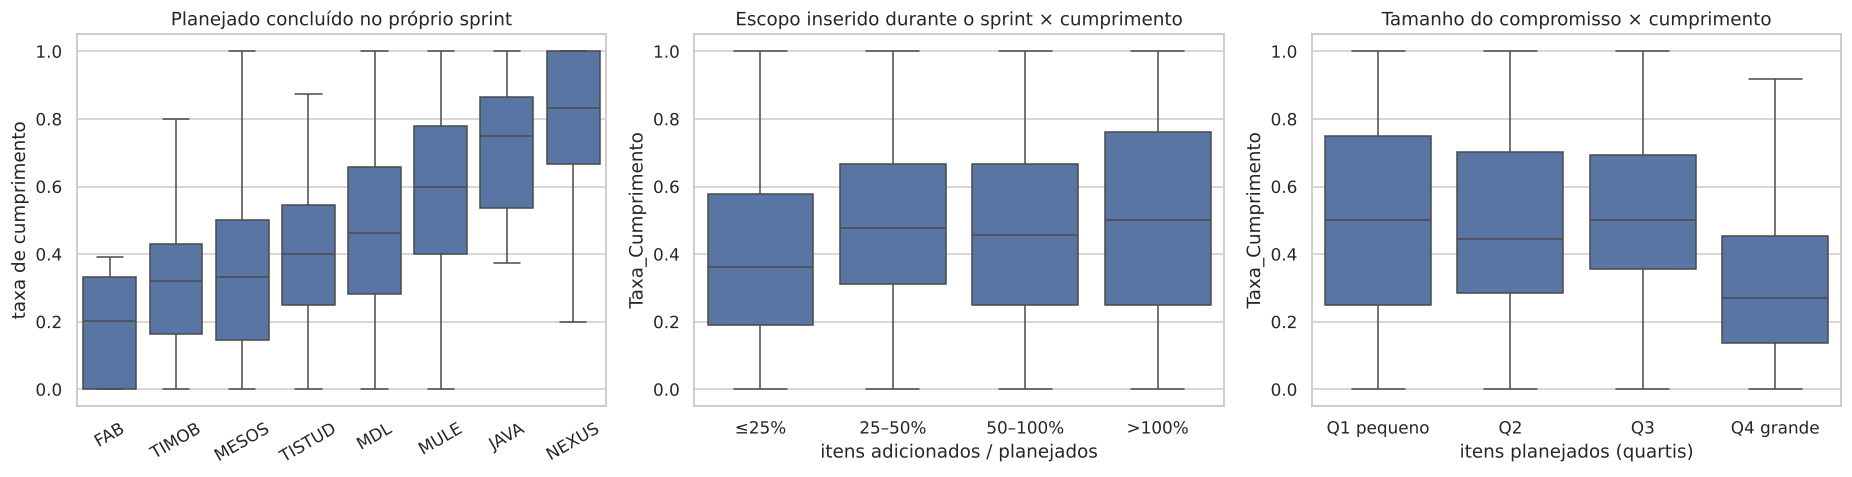

Spearman Pct_Escopo_Adicionado    × taxa de cumprimento: rho = +0.146 (p = 5.2e-06)
Spearman Itens_Planejados         × taxa de cumprimento: rho = -0.181 (p = 1.4e-08)
Spearman Pessoas_No_Sprint        × taxa de cumprimento: rho = -0.221 (p = 3.8e-12)
Spearman Pct_Bugs_Planejados      × taxa de cumprimento: rho = +0.086 (p = 7.1e-03)
Spearman Duracao_Dias             × taxa de cumprimento: rho = -0.030 (p = 3.5e-01)

Previsibilidade: usar a média dos 3 sprints anteriores como previsão de velocity erra, na mediana, 57%.


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=spr, x="Project_Key", y="Taxa_Cumprimento", order=tab.index, ax=ax[0], showfliers=False)
ax[0].set(title="Planejado concluído no próprio sprint", xlabel="", ylabel="taxa de cumprimento")
ax[0].tick_params(axis="x", rotation=30)
spr["Faixa_Escopo_Adicionado"] = pd.cut(spr.Pct_Escopo_Adicionado, [-.01, .25, .5, 1, np.inf], labels=["≤25%", "25–50%", "50–100%", ">100%"])
sns.boxplot(data=spr, x="Faixa_Escopo_Adicionado", y="Taxa_Cumprimento", ax=ax[1], showfliers=False)
ax[1].set(title="Escopo inserido durante o sprint × cumprimento", xlabel="itens adicionados / planejados")
spr["Faixa_Tamanho"] = pd.qcut(spr.Itens_Planejados, 4, labels=["Q1 pequeno", "Q2", "Q3", "Q4 grande"])
sns.boxplot(data=spr, x="Faixa_Tamanho", y="Taxa_Cumprimento", ax=ax[2], showfliers=False)
ax[2].set(title="Tamanho do compromisso × cumprimento", xlabel="itens planejados (quartis)")
salvar("15_sprints_cumprimento")

for v in ["Pct_Escopo_Adicionado", "Itens_Planejados", "Pessoas_No_Sprint", "Pct_Bugs_Planejados", "Duracao_Dias"]:
    r, p = stats.spearmanr(spr[v], spr.Taxa_Cumprimento, nan_policy="omit")
    print(f"Spearman {v:24s} × taxa de cumprimento: rho = {r:+.3f} (p = {p:.1e})")
# Previsibilidade: a velocity dos últimos sprints prevê a do próximo?
v = spr.dropna(subset=["Velocity_Media_3_Anteriores"])
v = v[v.Velocity_Media_3_Anteriores > 0]
erro = (v.Velocity_SP - v.Velocity_Media_3_Anteriores).abs() / v.Velocity_Media_3_Anteriores
print(f"\nPrevisibilidade: usar a média dos 3 sprints anteriores como previsão de velocity erra, na mediana, {erro.median():.0%}.")

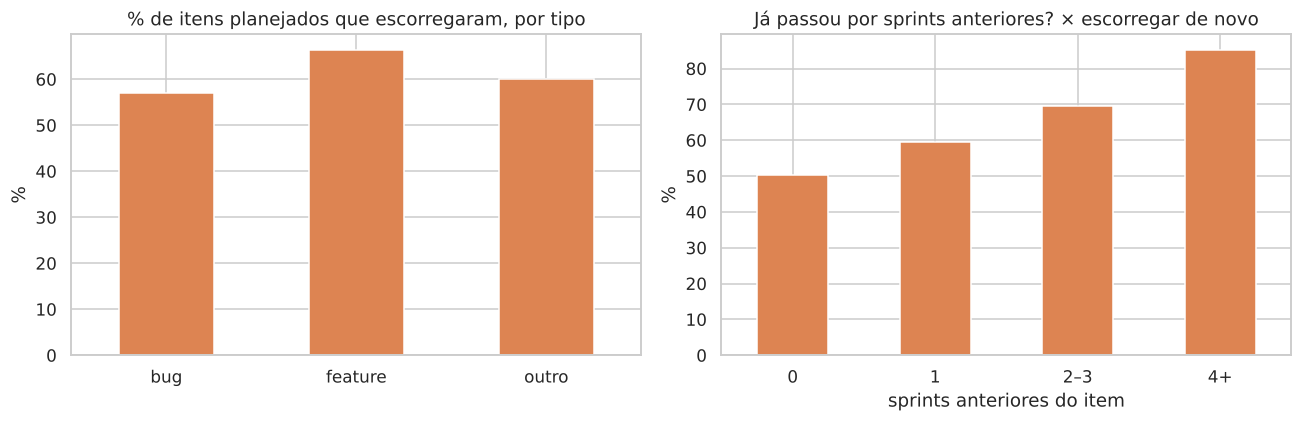

Modelo: prever, no início do sprint, se um item planejado NÃO será concluído dentro dele
Treino: 9,880 itens (até 01/2018) | Teste: 4,239 itens


,AUC,PR_AUC (precisão média),taxa_base_positivos,recall_positivos,precisao_positivos,F1_macro
modelo,,,,,,
Baseline (classe mais frequente),0.500,0.750,0.75,1.000,0.750,0.429
Regressão Logística,0.693,0.869,0.75,0.796,0.804,0.605
Random Forest,0.685,0.848,0.75,0.789,0.814,0.619
XGBoost,0.679,0.847,0.75,0.746,0.816,0.609


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(its.groupby("Tipo_Item").Nao_Concluiu_No_Sprint.mean() * 100).plot.bar(ax=ax[0], rot=0, color="#DD8452")
ax[0].set(title="% de itens planejados que escorregaram, por tipo", xlabel="", ylabel="%")
its["Faixa_Carregado"] = pd.cut(its.Vezes_Em_Sprints_Anteriores, [-1, 0, 1, 3, np.inf], labels=["0", "1", "2–3", "4+"])
(its.groupby("Faixa_Carregado").Nao_Concluiu_No_Sprint.mean() * 100).plot.bar(ax=ax[1], rot=0, color="#DD8452")
ax[1].set(title="Já passou por sprints anteriores? × escorregar de novo", xlabel="sprints anteriores do item", ylabel="%")
salvar("16_sprints_itens")

print("Modelo: prever, no início do sprint, se um item planejado NÃO será concluído dentro dele")
CAT_S = ["Project_Key", "Tipo_Item"]
NUM_S = ["Prioridade_Nivel", "Story_Point", "Tem_Story_Point", "Tamanho_Descricao", "Qtd_Componentes",
         "Tem_Responsavel", "Itens_Do_Responsavel_No_Sprint", "Vezes_Em_Sprints_Anteriores",
         "Duracao_Sprint_Dias", "Itens_Planejados", "SP_Planejados", "Pessoas_No_Sprint", "Taxa_Cumprimento_Anterior"]
corte_s = its.Start_Date.quantile(0.7)
tr_s, te_s = its[its.Start_Date < corte_s], its[its.Start_Date >= corte_s]
print(f"Treino: {len(tr_s):,} itens (até {corte_s:%m/%Y}) | Teste: {len(te_s):,} itens")
res_s, fit_s = avaliar_bin(tr_s[CAT_S + NUM_S], tr_s.Nao_Concluiu_No_Sprint, te_s[CAT_S + NUM_S], te_s.Nao_Concluiu_No_Sprint, CAT_S, NUM_S)
res_s

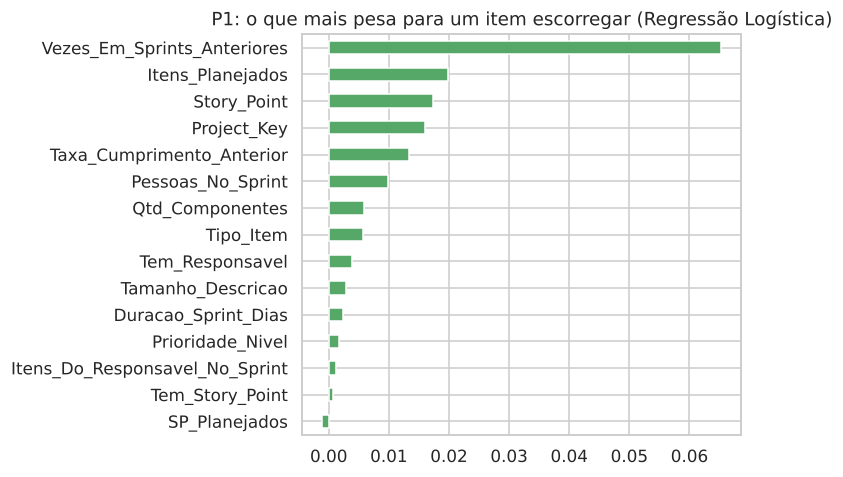

In [22]:
melhor_s = res_s.drop(index="Baseline (classe mais frequente)").AUC.idxmax()
pi = permutation_importance(fit_s[melhor_s], te_s[CAT_S + NUM_S], te_s.Nao_Concluiu_No_Sprint, scoring="roc_auc",
                            n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
fig, ax = plt.subplots(figsize=(7, 4.5))
pd.Series(pi.importances_mean, index=CAT_S + NUM_S).sort_values().plot.barh(ax=ax, color="#55A868")
ax.set_title(f"P1: o que mais pesa para um item escorregar ({melhor_s})")
salvar("17_sprints_modelo")

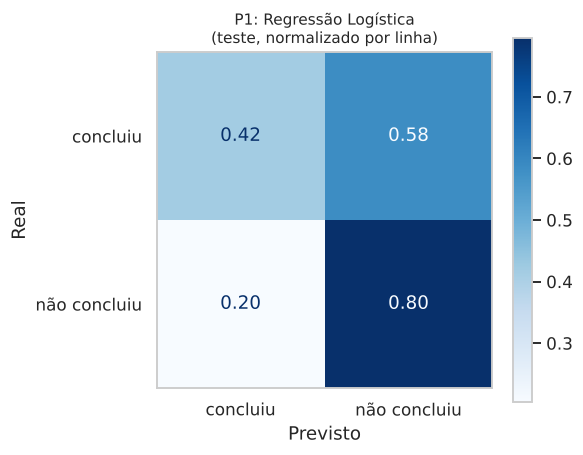

In [23]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_estimator(fit_s[melhor_s], te_s[CAT_S + NUM_S], te_s.Nao_Concluiu_No_Sprint, display_labels=["concluiu", "não concluiu"], normalize="true",
                                      values_format=".2f", cmap="Blues", ax=ax)
ax.set_title("P1: " + melhor_s + "\n(teste, normalizado por linha)", fontsize=10); ax.grid(False); ax.set(xlabel="Previsto", ylabel="Real")
salvar("17b_sprints_matriz_confusao")

## 6.2 Capacidade: quanto vai para sustentação e quanto para evolução? (P3)
`base_capacidade_mensal.csv` traz, mês a mês e por projeto, os itens resolvidos em **sustentação** (bugs) e em **evolução** (features e melhorias). A pergunta central é se um pico de bugs depois de uma release *rouba* capacidade das entregas seguintes.

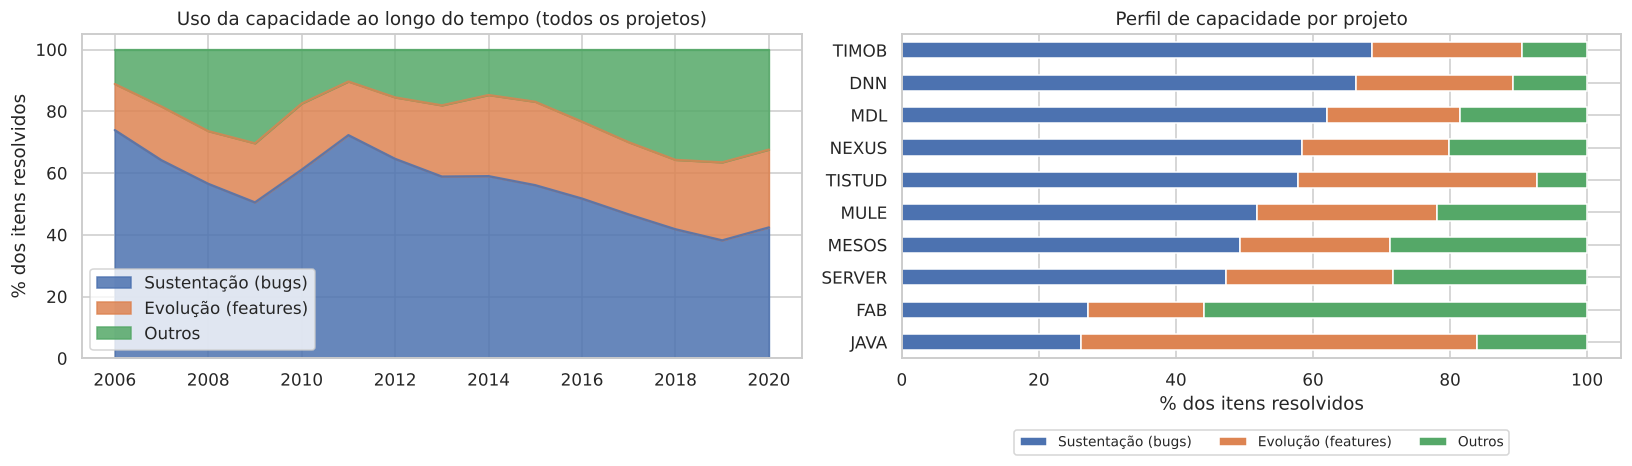

Em média, 53.3% da capacidade foi para correção de bugs.


In [24]:
cap = pd.read_csv("bases/base_capacidade_mensal.csv", parse_dates=["Mes"])
cap["Ano"] = cap.Mes.dt.year
anual = cap.groupby("Ano")[["Sustentacao_Bugs", "Evolucao_Features", "Outros"]].sum()
anual = anual[anual.sum(axis=1) > 500]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
NOMES_CAP = {"Sustentacao_Bugs": "Sustentação (bugs)", "Evolucao_Features": "Evolução (features)", "Outros": "Outros"}
(anual.div(anual.sum(axis=1), axis=0) * 100).rename(columns=NOMES_CAP).plot.area(ax=ax[0], alpha=.85)
ax[0].set(title="Uso da capacidade ao longo do tempo (todos os projetos)", ylabel="% dos itens resolvidos", xlabel="")
ax[0].legend(loc="lower left")
por_proj = cap.groupby("Project_Key")[["Sustentacao_Bugs", "Evolucao_Features", "Outros"]].sum()
(por_proj.div(por_proj.sum(axis=1), axis=0) * 100).sort_values("Sustentacao_Bugs").rename(columns=NOMES_CAP).plot.barh(stacked=True, ax=ax[1])
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=9)
ax[1].set(title="Perfil de capacidade por projeto", xlabel="% dos itens resolvidos", ylabel="")
salvar("09_capacidade_sustentacao_evolucao")
print(f"Em média, {cap.Sustentacao_Bugs.sum() / cap.Itens_Resolvidos.sum():.1%} da capacidade foi para correção de bugs.")

In [25]:
# Um mês com muitos bugs novos é seguido por um mês com mais capacidade em sustentação?
# Para não comparar projetos de portes diferentes, cada série é padronizada dentro do projeto (z-score).
c = cap.sort_values(["Project_Key", "Mes"]).copy()
c["z_bugs_abertos"] = c.groupby("Project_Key").Bugs_Abertos_No_Mes.transform(lambda s: (s - s.mean()) / s.std())
linhas = []
for lag in range(0, 4):
    c[f"pct_sust_lag{lag}"] = c.groupby("Project_Key").Pct_Sustentacao.shift(-lag)
    c[f"feat_lag{lag}"] = c.groupby("Project_Key").Evolucao_Features.shift(-lag)
    c[f"z_feat_lag{lag}"] = c.groupby("Project_Key")[f"feat_lag{lag}"].transform(lambda s: (s - s.mean()) / s.std())
    r1, p1 = stats.spearmanr(c.z_bugs_abertos, c[f"pct_sust_lag{lag}"], nan_policy="omit")
    r2, p2 = stats.spearmanr(c.z_bugs_abertos, c[f"z_feat_lag{lag}"], nan_policy="omit")
    linhas.append((f"t+{lag}", r1, p1, r2, p2))
display(pd.DataFrame(linhas, columns=["mês", "rho_%sustentação", "p", "rho_features_entregues", "p "]).round(4))

# No nível de release: muitos bugs na release R → a release seguinte (R+1) entrega mais correção e menos feature?
r = rel.sort_values(["Project_Key", "Release_Date"]).copy()
r = r[r.Tipo_Release != "pre-release"]
for col in ["Pct_Correcoes", "Pct_Features", "Qtd_Features"]:
    r[f"prox_{col}"] = r.groupby("Project_Key")[col].shift(-1)
res = [(col, *stats.spearmanr(r.Bugs_Por_Item_Entregue, r[f"prox_{col}"], nan_policy="omit"))
       for col in ["Pct_Correcoes", "Pct_Features", "Qtd_Features"]]
print("Bugs por item entregue na release R × composição da release seguinte (R+1):")
display(pd.DataFrame(res, columns=["variável em R+1", "rho_spearman", "p_valor"]).round(4))

,mês,rho_%sustentação,p,rho_features_entregues,p
0,t+0,0.0793,0.0056,0.4472,0.0
1,t+1,0.0525,0.0684,0.3415,0.0
2,t+2,0.0066,0.8205,0.3039,0.0
3,t+3,-0.0261,0.3683,0.2831,0.0


Bugs por item entregue na release R × composição da release seguinte (R+1):


,variável em R+1,rho_spearman,p_valor
0,Pct_Correcoes,0.0793,0.0087
1,Pct_Features,0.0227,0.4534
2,Qtd_Features,0.0766,0.0113


## 6.3 Risco de pessoa-chave e sobrecarga (P5)
- **Carga do responsável:** itens em aberto atribuídos à mesma pessoa no dia em que o bug foi aberto.
- **Concentração (*bus factor*):** quantas pessoas resolvem metade dos bugs de cada projeto. Responde com dado real ao cenário "saída de uma pessoa-chave".

,responsaveis_distintos,pessoas_que_resolvem_50pct,pct_do_maior_responsavel
Project_Key,,,
JAVA,20,2,47.8
DNN,19,3,34.1
TISTUD,41,3,22.3
NEXUS,64,5,12.5
MULE,99,9,9.2
TIMOB,114,10,11.1
MDL,420,13,12.9
FAB,243,13,8.8
MESOS,171,14,7.8


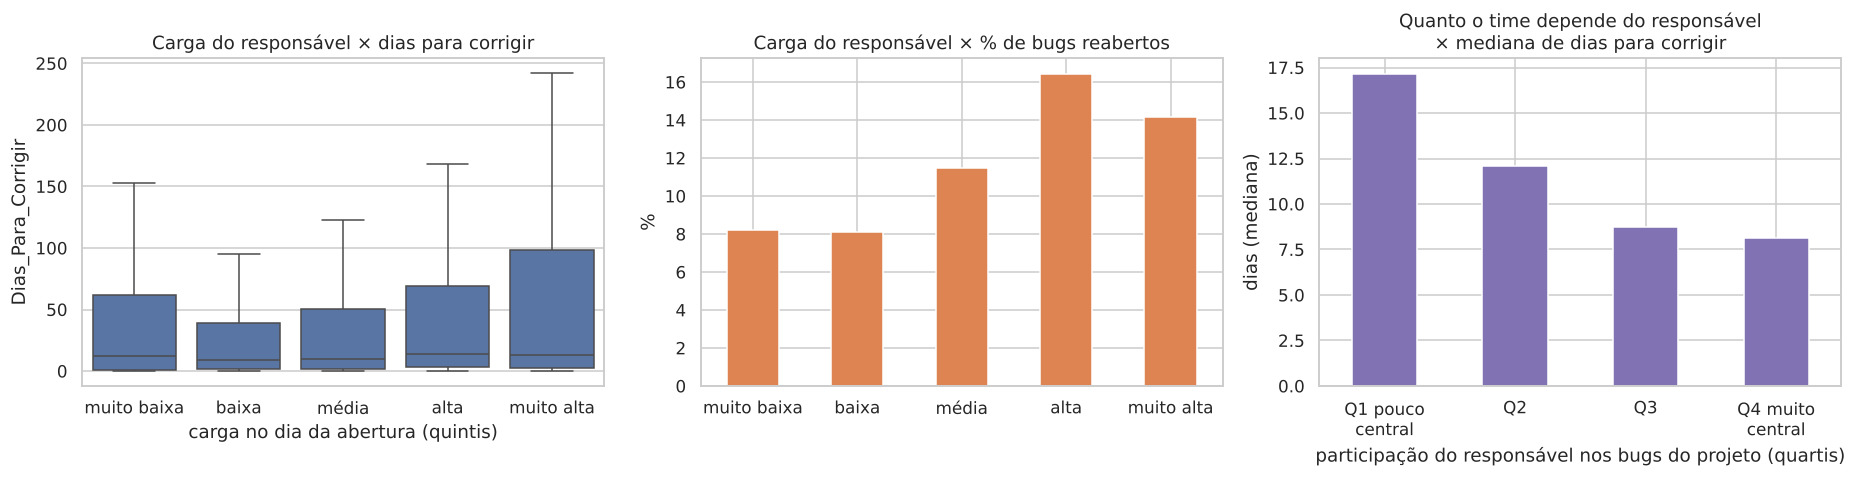

Kruskal-Wallis dias × faixa de carga: H = 285.0, p = 1.91e-60
Qui-quadrado reabertura × faixa de carga: chi² = 551.7, p = 4.34e-118
Spearman carga × dias, dentro de cada projeto:


Project_Key,DNN,FAB,JAVA,MDL,MESOS,MULE,NEXUS,SERVER,TIMOB,TISTUD
rho,0.108,-0.112,0.189,-0.146,-0.026,0.013,-0.1,-0.078,0.368,0.105


Kruskal-Wallis dias × centralidade do responsável: H = 894.0, p = 1.73e-193


In [26]:
def bus_factor(s, alvo=0.5):
    p = s.value_counts(normalize=True).cumsum()
    return int((p < alvo).sum() + 1)

bf = bugs.dropna(subset=["Carga_Responsavel"]).copy()
conc_proj = bugs.dropna(subset=["Responsavel_ID"]).groupby("Project_Key").agg(
    responsaveis_distintos=("Responsavel_ID", "nunique"),
    pessoas_que_resolvem_50pct=("Responsavel_ID", bus_factor),
    pct_do_maior_responsavel=("Responsavel_ID", lambda s: s.value_counts(normalize=True).iloc[0] * 100))
display(conc_proj.round(1).sort_values("pessoas_que_resolvem_50pct"))

bf["Faixa_Carga"] = pd.qcut(bf.Carga_Responsavel, 5, labels=["muito baixa", "baixa", "média", "alta", "muito alta"])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=bf, x="Faixa_Carga", y="Dias_Para_Corrigir", showfliers=False, ax=ax[0])
ax[0].set(title="Carga do responsável × dias para corrigir", xlabel="carga no dia da abertura (quintis)")
(bf.groupby("Faixa_Carga").Foi_Reaberto.mean() * 100).plot.bar(ax=ax[1], color="#DD8452", rot=0)
ax[1].set(title="Carga do responsável × % de bugs reabertos", xlabel="", ylabel="%")
bf["Faixa_Centralidade"] = pd.qcut(bf.Participacao_Responsavel_No_Projeto, 4,
                                   labels=["Q1 pouco\ncentral", "Q2", "Q3", "Q4 muito\ncentral"])
conc = bf.groupby("Faixa_Centralidade").Dias_Para_Corrigir.median()
conc.plot.bar(ax=ax[2], color="#8172B3", rot=0)
ax[2].set(title="Quanto o time depende do responsável\n× mediana de dias para corrigir",
          xlabel="participação do responsável nos bugs do projeto (quartis)", ylabel="dias (mediana)")
salvar("10_carga_concentracao")

h, p = stats.kruskal(*[g.Dias_Para_Corrigir for _, g in bf.groupby("Faixa_Carga")])
print(f"Kruskal-Wallis dias × faixa de carga: H = {h:.1f}, p = {p:.2e}")
chi2, p2, _, _ = stats.chi2_contingency(pd.crosstab(bf.Faixa_Carga, bf.Foi_Reaberto))
print(f"Qui-quadrado reabertura × faixa de carga: chi² = {chi2:.1f}, p = {p2:.2e}")
rho = bf.groupby("Project_Key").apply(lambda g: stats.spearmanr(g.Carga_Responsavel, g.Dias_Para_Corrigir)[0])
print("Spearman carga × dias, dentro de cada projeto:"); display(rho.round(3).to_frame("rho").T)
h, p = stats.kruskal(*[g.Dias_Para_Corrigir for _, g in bf.groupby("Faixa_Centralidade")])
print(f"Kruskal-Wallis dias × centralidade do responsável: H = {h:.1f}, p = {p:.2e}")

## 6.4 Retrabalho: o que faz um bug ser reaberto? (P7)
**Momento da previsão:** quando o bug é marcado como resolvido. Por isso o tempo que levou para corrigir pode entrar como variável. A pergunta prática é se dá para sinalizar, no fechamento, quais correções merecem uma validação extra.

% de bugs reabertos por projeto (depende muito do fluxo de cada time):


Project_Key,FAB,SERVER,MESOS,JAVA,NEXUS,MDL,MULE,TIMOB,DNN,TISTUD
% reabertos,0.0,1.2,4.0,5.2,5.8,11.6,13.9,24.7,27.6,34.2


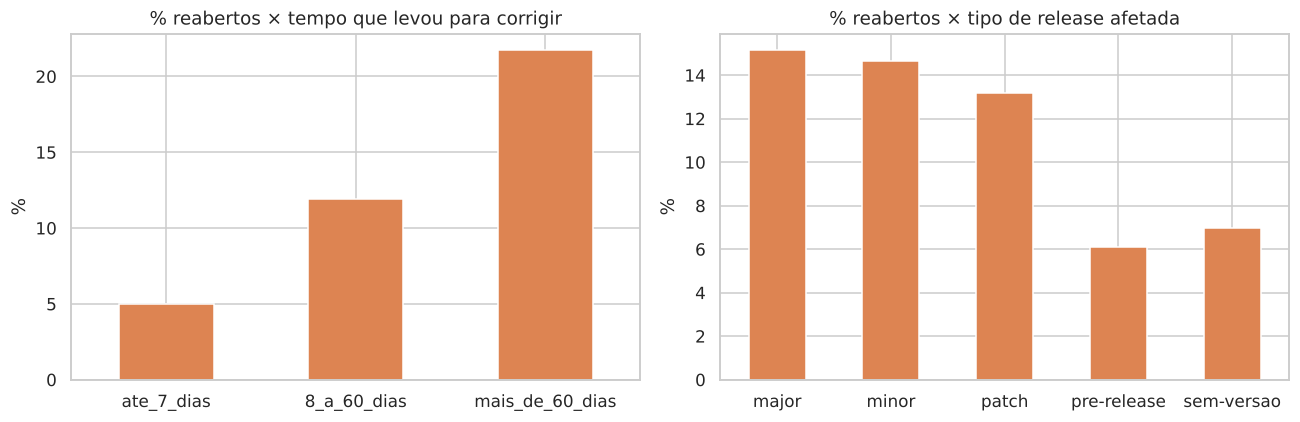

Taxa de reabertura: treino 14.5% | teste 4.2% (a queda vem de mudanças de fluxo: vários times, como SERVER, MESOS e NEXUS, deixaram de usar o status Reopened; os projetos que mais reabrem perderam peso; e bugs recentes tiveram menos tempo para serem reabertos)


,AUC,PR_AUC (precisão média),taxa_base_positivos,recall_positivos,precisao_positivos,F1_macro
modelo,,,,,,
Baseline (classe mais frequente),0.500,0.042,0.042,0.000,0.000,0.489
Regressão Logística,0.822,0.135,0.042,0.674,0.118,0.534
Random Forest,0.842,0.165,0.042,0.662,0.136,0.558
XGBoost,0.801,0.131,0.042,0.610,0.105,0.521


In [27]:
print("% de bugs reabertos por projeto (depende muito do fluxo de cada time):")
display((bugs.groupby("Project_Key").Foi_Reaberto.mean() * 100).round(1).sort_values().to_frame("% reabertos").T)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bugs["Faixa_Correcao_cat"] = pd.Categorical(bugs.Faixa_Correcao, CLASSES, ordered=True)
(bugs.groupby("Faixa_Correcao_cat").Foi_Reaberto.mean() * 100).plot.bar(ax=ax[0], rot=0, color="#DD8452")
ax[0].set(title="% reabertos × tempo que levou para corrigir", xlabel="", ylabel="%")
(bugs.groupby("Tipo_Release_Afetada").Foi_Reaberto.mean() * 100).reindex(ORDEM_TIPO + ["sem-versao"]).plot.bar(ax=ax[1], rot=0, color="#DD8452")
ax[1].set(title="% reabertos × tipo de release afetada", xlabel="", ylabel="%")
salvar("11_reabertura_descritivo")

NUM_RE = NUM_B + ["Dias_Para_Corrigir", "Carga_Responsavel", "Participacao_Responsavel_No_Projeto", "Tem_Responsavel"]
print(f"Taxa de reabertura: treino {tr_b.Foi_Reaberto.mean():.1%} | teste {te_b.Foi_Reaberto.mean():.1%} "
      "(a queda vem de mudanças de fluxo: vários times, como SERVER, MESOS e NEXUS, deixaram de usar o status Reopened; os projetos que mais reabrem perderam peso; e bugs recentes tiveram menos tempo para serem reabertos)")
res_re, fit_re = avaliar_bin(tr_b[CAT_B + NUM_RE], tr_b.Foi_Reaberto, te_b[CAT_B + NUM_RE], te_b.Foi_Reaberto, CAT_B, NUM_RE)
res_re

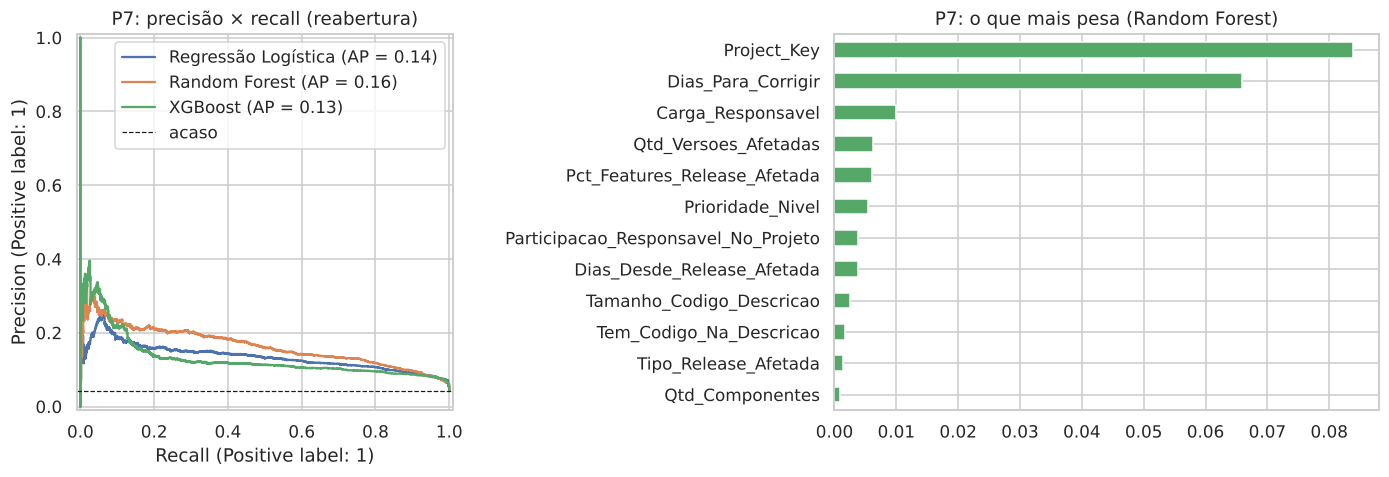

In [28]:
melhor_re = res_re.drop(index="Baseline (classe mais frequente)")["PR_AUC (precisão média)"].idxmax()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for nome in ["Regressão Logística", "Random Forest", "XGBoost"]:
    PrecisionRecallDisplay.from_estimator(fit_re[nome], te_b[CAT_B + NUM_RE], te_b.Foi_Reaberto, ax=ax[0], name=nome)
ax[0].axhline(te_b.Foi_Reaberto.mean(), color="k", ls="--", lw=.8, label="acaso")
ax[0].set_title("P7: precisão × recall (reabertura)"); ax[0].legend(loc="upper right")
amostra = te_b.sample(min(5000, len(te_b)), random_state=RANDOM_STATE)
pi = permutation_importance(fit_re[melhor_re], amostra[CAT_B + NUM_RE], amostra.Foi_Reaberto,
                            scoring="average_precision", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
pd.Series(pi.importances_mean, index=CAT_B + NUM_RE).sort_values().tail(12).plot.barh(ax=ax[1], color="#55A868")
ax[1].set_title(f"P7: o que mais pesa ({melhor_re})")
salvar("12_reabertura_modelo")

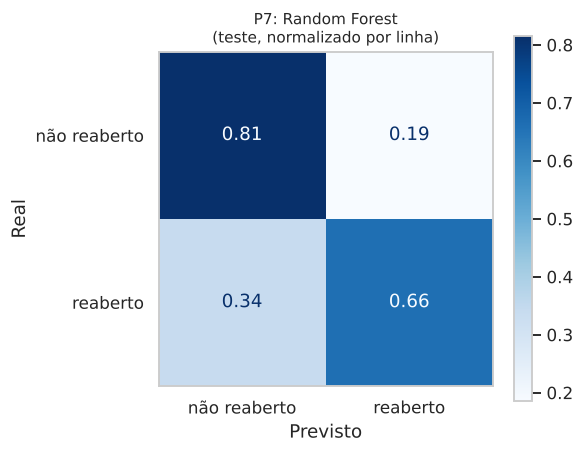

In [29]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_estimator(fit_re[melhor_re], te_b[CAT_B + NUM_RE], te_b.Foi_Reaberto, display_labels=["não reaberto", "reaberto"], normalize="true",
                                      values_format=".2f", cmap="Blues", ax=ax)
ax.set_title("P7: " + melhor_re + "\n(teste, normalizado por linha)", fontsize=10); ax.grid(False); ax.set(xlabel="Previsto", ylabel="Real")
salvar("12b_reabertura_matriz_confusao")

## 6.5 Impacto em cliente: quais bugs vão "estourar"? (P8)
Proxies de impacto melhores que a prioridade sozinha:
- **Duplicatas:** outras pessoas reportaram o mesmo problema, sinal de muitos afetados.
- **Escalada de prioridade:** o bug ficou mais grave depois de aberto.

`Alto_Impacto = 1` quando há pelo menos uma das duas. **Momento da previsão:** a abertura do bug, com as mesmas variáveis do Modelo 1.

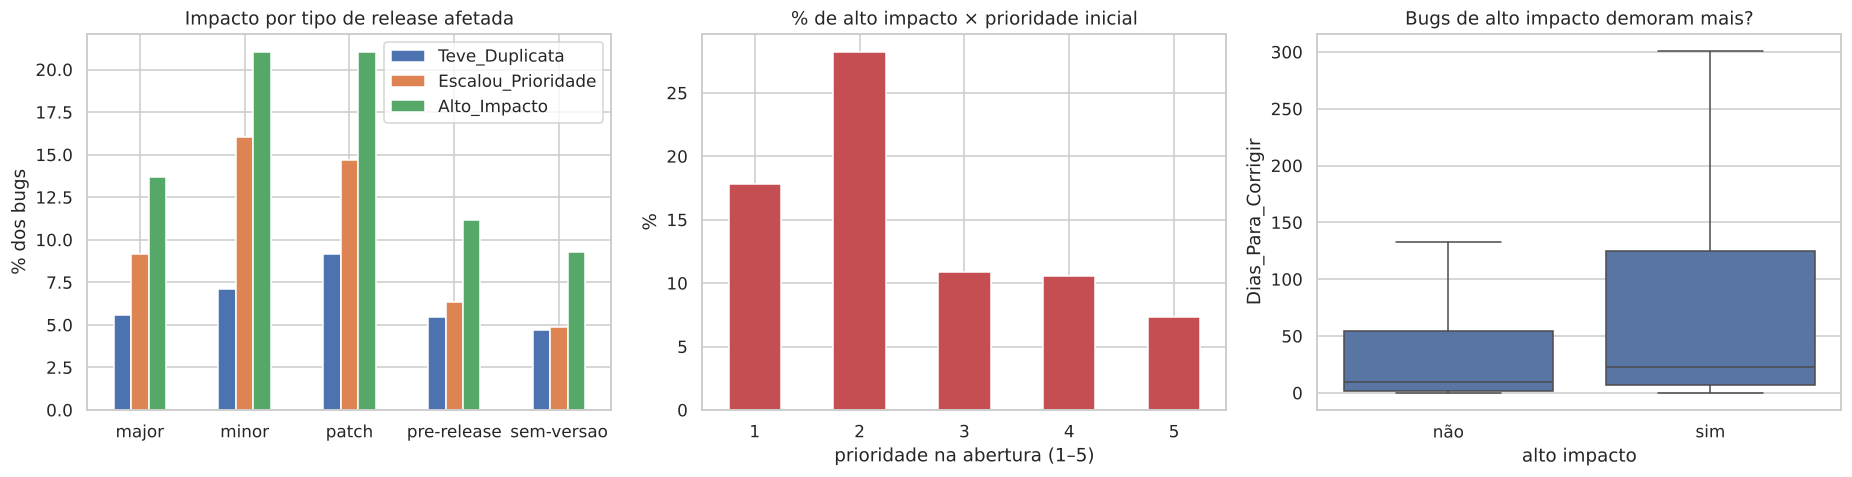

Qui-quadrado alto impacto × tipo de release afetada: chi² = 1183.1, p = 7.22e-255
Mann-Whitney dias (alto impacto × demais): p = 1.36e-262; medianas = 23.1 × 9.9 dias


,AUC,PR_AUC (precisão média),taxa_base_positivos,recall_positivos,precisao_positivos,F1_macro
modelo,,,,,,
Baseline (classe mais frequente),0.500,0.148,0.148,0.000,0.000,0.460
Regressão Logística,0.677,0.264,0.148,0.562,0.257,0.577
Random Forest,0.691,0.287,0.148,0.453,0.303,0.609
XGBoost,0.679,0.280,0.148,0.494,0.289,0.603


In [30]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
imp_tipo = bugs.groupby("Tipo_Release_Afetada")[["Escalou_Prioridade", "Alto_Impacto"]].mean().reindex(ORDEM_TIPO + ["sem-versao"]) * 100
imp_tipo["Teve_Duplicata"] = bugs.groupby("Tipo_Release_Afetada").Qtd_Duplicados.apply(lambda s: (s > 0).mean() * 100)
imp_tipo[["Teve_Duplicata", "Escalou_Prioridade", "Alto_Impacto"]].plot.bar(ax=ax[0], rot=0)
ax[0].set(title="Impacto por tipo de release afetada", ylabel="% dos bugs", xlabel="")
(bugs.groupby("Prioridade_Nivel").Alto_Impacto.mean() * 100).plot.bar(ax=ax[1], rot=0, color="#C44E52")
ax[1].set(title="% de alto impacto × prioridade inicial", xlabel="prioridade na abertura (1–5)", ylabel="%")
sns.boxplot(data=bugs, x="Alto_Impacto", y="Dias_Para_Corrigir", showfliers=False, ax=ax[2])
ax[2].set(title="Bugs de alto impacto demoram mais?", xticklabels=["não", "sim"], xlabel="alto impacto")
salvar("13_impacto_descritivo")

chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(bugs.Tipo_Release_Afetada, bugs.Alto_Impacto))
print(f"Qui-quadrado alto impacto × tipo de release afetada: chi² = {chi2:.1f}, p = {p:.2e}")
u, p = stats.mannwhitneyu(bugs.loc[bugs.Alto_Impacto == 1, "Dias_Para_Corrigir"], bugs.loc[bugs.Alto_Impacto == 0, "Dias_Para_Corrigir"])
print(f"Mann-Whitney dias (alto impacto × demais): p = {p:.2e}; medianas = "
      f"{bugs.loc[bugs.Alto_Impacto == 1, 'Dias_Para_Corrigir'].median():.1f} × {bugs.loc[bugs.Alto_Impacto == 0, 'Dias_Para_Corrigir'].median():.1f} dias")

res_im, fit_im = avaliar_bin(tr_b[CAT_B + NUM_B], tr_b.Alto_Impacto, te_b[CAT_B + NUM_B], te_b.Alto_Impacto, CAT_B, NUM_B)
res_im

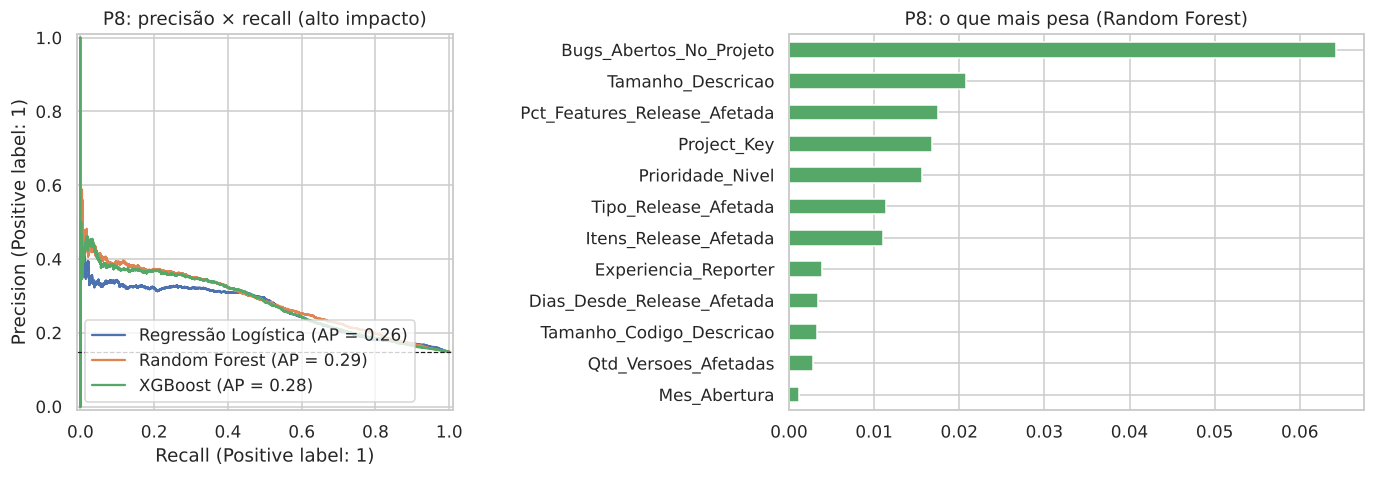

In [31]:
melhor_im = res_im.drop(index="Baseline (classe mais frequente)")["PR_AUC (precisão média)"].idxmax()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for nome in ["Regressão Logística", "Random Forest", "XGBoost"]:
    PrecisionRecallDisplay.from_estimator(fit_im[nome], te_b[CAT_B + NUM_B], te_b.Alto_Impacto, ax=ax[0], name=nome)
ax[0].axhline(te_b.Alto_Impacto.mean(), color="k", ls="--", lw=.8)
ax[0].set_title("P8: precisão × recall (alto impacto)")
amostra = te_b.sample(min(5000, len(te_b)), random_state=RANDOM_STATE)
pi = permutation_importance(fit_im[melhor_im], amostra[CAT_B + NUM_B], amostra.Alto_Impacto,
                            scoring="average_precision", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
pd.Series(pi.importances_mean, index=CAT_B + NUM_B).sort_values().tail(12).plot.barh(ax=ax[1], color="#55A868")
ax[1].set_title(f"P8: o que mais pesa ({melhor_im})")
salvar("14_impacto_modelo")

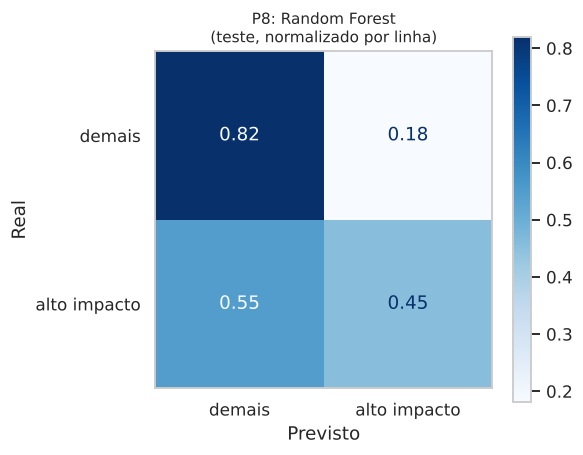

In [32]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_estimator(fit_im[melhor_im], te_b[CAT_B + NUM_B], te_b.Alto_Impacto, display_labels=["demais", "alto impacto"], normalize="true",
                                      values_format=".2f", cmap="Blues", ax=ax)
ax.set_title("P8: " + melhor_im + "\n(teste, normalizado por linha)", fontsize=10); ax.grid(False); ax.set(xlabel="Previsto", ylabel="Real")
salvar("14b_impacto_matriz_confusao")

# 7. Robustez e validação das escolhas metodológicas
Esta seção testa as principais escolhas do trabalho contra alternativas que uma banca poderia sugerir:
1. **Poisson × Binomial Negativa** para a contagem de bugs pós-release;
2. **Análise de sobrevivência** (Kaplan-Meier e regressão de Cox) para o tempo de correção, incluindo os bugs que **não** foram corrigidos (observações censuradas);
3. **Ajuste de hiperparâmetros** com validação temporal;
4. **Intervalos de confiança por bootstrap** para as métricas e para a diferença entre modelos;
5. **Calibração** das probabilidades previstas.

## 7.1 Poisson × Binomial Negativa
A regressão de Poisson supõe variância igual à média. Se os dados tiverem **sobredispersão** (variância muito maior que a média), a Poisson subestima os erros-padrão e "acha" efeitos significativos demais; a Binomial Negativa corrige isso.

In [33]:
import statsmodels.api as sm
formula_nb = ("Bugs_Pos_Release ~ C(Tipo_Release, Treatment('minor')) + pct_features_10pp + pct_alta"
              " + log_itens + log_componentes + log_dias_ant + C(Project_Key)")
pois = smf.glm(formula_nb, data=d, family=sm.families.Poisson()).fit()
disp = pois.pearson_chi2 / pois.df_resid
print(f"Média de bugs pós-release = {d.Bugs_Pos_Release.mean():.1f} | variância = {d.Bugs_Pos_Release.var():.1f}")
print(f"Dispersão de Pearson da Poisson = {disp:.1f} (≈ 1 seria adequado à Poisson)")
print(f"AIC Poisson = {pois.aic:,.0f} | AIC Binomial Negativa = {nb.aic:,.0f} (menor é melhor)")
print(f"Parâmetro de sobredispersão (alpha) da Binomial Negativa = {nb.params['alpha']:.2f} "
      f"(IC95%: {nb.conf_int().loc['alpha', 0]:.2f} a {nb.conf_int().loc['alpha', 1]:.2f})")

Média de bugs pós-release = 37.1 | variância = 4161.4
Dispersão de Pearson da Poisson = 34.7 (≈ 1 seria adequado à Poisson)
AIC Poisson = 38,438 | AIC Binomial Negativa = 10,469 (menor é melhor)
Parâmetro de sobredispersão (alpha) da Binomial Negativa = 1.08 (IC95%: 0.99 a 1.17)


## 7.2 Tempo de correção como análise de sobrevivência
Nas seções 3 e 4, o tempo de correção foi analisado **apenas nos bugs corrigidos**. Bugs que continuam abertos ou que foram encerrados sem correção ficam de fora, e isso pode distorcer as estimativas (viés de seleção). A análise de sobrevivência usa **todos os bugs** do mesmo período: os não corrigidos entram como **censurados**, isto é, sabe-se apenas que não foram corrigidos até a data observada.
- **Kaplan-Meier:** proporção de bugs ainda não corrigidos ao longo do tempo, por grupo; teste log-rank para comparar grupos.
- **Regressão de Cox:** efeito de cada variável na "velocidade" de correção. *Hazard ratio* (HR) > 1 indica correção mais rápida; < 1, mais lenta. Estratificada por projeto.

Bugs na base de sobrevivência: 105,637


,% dos bugs
Situacao_Final,
corrigido,52.7
encerrado_sem_correcao,35.1
aberto_na_coleta,12.2


Mediana do tempo de correção – só bugs corrigidos: 11.8 dias | Kaplan-Meier com censura: 131.3 dias
Log-rank Tipo_Release_Afetada: chi² = 3,072, p = 0.0e+00


,Tipo_Release_Afetada,n,mediana_KM_dias
0,major,8092,44.1
1,minor,28071,138.0
2,patch,38103,453.4
3,pre-release,3103,15.7
4,sem-versao,28268,48.3


Log-rank Prioridade_Nivel: chi² = 4,118, p = 0.0e+00


,Prioridade_Nivel,n,mediana_KM_dias
0,1,3472,NaN
1,2,39207,531.2
2,3,45412,55.2
3,4,15345,74.5
4,5,2201,8.4


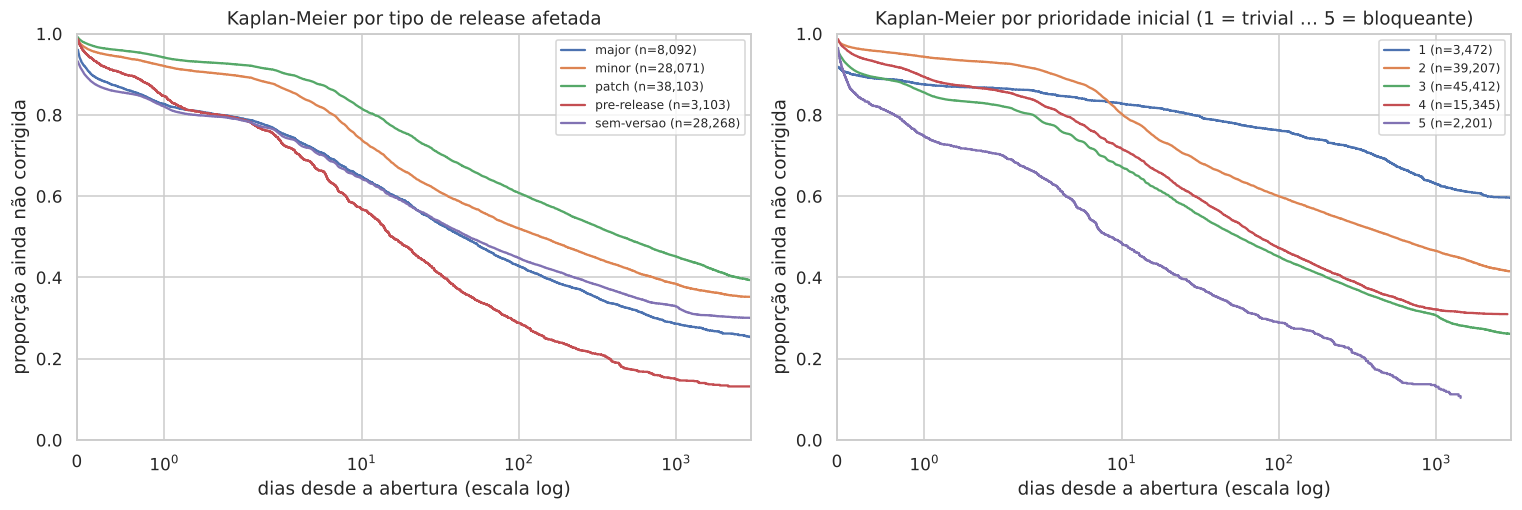

In [34]:
from statsmodels.duration.survfunc import SurvfuncRight, survdiff
from statsmodels.duration.hazard_regression import PHReg

surv = pd.read_csv("bases/base_bugs_sobrevivencia.csv", parse_dates=["Creation_Date"])
surv["Tempo_Dias"] = surv.Tempo_Dias.clip(lower=0.01)
print(f"Bugs na base de sobrevivência: {len(surv):,}")
display(surv.Situacao_Final.value_counts(normalize=True).mul(100).round(1).to_frame("% dos bugs"))

med_sel = bugs.Dias_Para_Corrigir.median()
km_all = SurvfuncRight(surv.Tempo_Dias, surv.Evento_Corrigido)
print(f"Mediana do tempo de correção – só bugs corrigidos: {med_sel:.1f} dias | "
      f"Kaplan-Meier com censura: {km_all.quantile(0.5):.1f} dias")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for grupo, titulo, a, ordem in [("Tipo_Release_Afetada", "por tipo de release afetada", ax[0], ORDEM_TIPO + ["sem-versao"]),
                                ("Prioridade_Nivel", "por prioridade inicial (1 = trivial … 5 = bloqueante)", ax[1], [1, 2, 3, 4, 5])]:
    linhas = []
    for g in ordem:
        s = surv[surv[grupo] == g]
        if len(s) < 50:
            continue
        km = SurvfuncRight(s.Tempo_Dias, s.Evento_Corrigido)
        a.step(km.surv_times, km.surv_prob, where="post", label=f"{g} (n={len(s):,})")
        linhas.append((g, len(s), km.quantile(0.5)))
    a.set(xscale="symlog", xlim=(0, 3000), ylim=(0, 1), xlabel="dias desde a abertura (escala log)",
          ylabel="proporção ainda não corrigida", title=f"Kaplan-Meier {titulo}")
    a.legend(fontsize=8)
    stat, p = survdiff(surv.Tempo_Dias, surv.Evento_Corrigido, surv[grupo])
    print(f"Log-rank {grupo}: chi² = {stat:,.0f}, p = {p:.1e}")
    display(pd.DataFrame(linhas, columns=[grupo, "n", "mediana_KM_dias"]).round(1))
salvar("18_sobrevivencia_kaplan_meier")

In [35]:
# Sensibilidade: bugs encerrados sem correção ("Won't Fix", "Duplicate" etc.) nunca serão corrigidos.
# Tratá-los como censurados aumenta o tempo estimado; excluí-los dá o cenário oposto.
cen = []
for rotulo, df_ in [("só bugs corrigidos (seções 3 e 4)", None),
                    ("Kaplan-Meier, encerrados sem correção excluídos", surv[surv.Situacao_Final != "encerrado_sem_correcao"]),
                    ("Kaplan-Meier, encerrados sem correção censurados", surv)]:
    linha = {"cenário": rotulo}
    for g in ORDEM_TIPO + ["sem-versao"]:
        if df_ is None:
            linha[g] = bugs.loc[bugs.Tipo_Release_Afetada == g, "Dias_Para_Corrigir"].median()
        else:
            s_ = df_[df_.Tipo_Release_Afetada == g]
            linha[g] = SurvfuncRight(s_.Tempo_Dias, s_.Evento_Corrigido).quantile(0.5)
    cen.append(linha)
print("Mediana de dias para corrigir, por tipo de release afetada, em cada cenário:")
pd.DataFrame(cen).set_index("cenário").round(1)

Mediana de dias para corrigir, por tipo de release afetada, em cada cenário:


,major,minor,patch,pre-release,sem-versao
cenário,,,,,
só bugs corrigidos (seções 3 e 4),7.4,13.0,20.9,7.1,6.2
"Kaplan-Meier, encerrados sem correção excluídos",10.8,27.9,44.9,7.6,13.7
"Kaplan-Meier, encerrados sem correção censurados",44.1,138.0,453.4,15.7,48.3


In [36]:
# Regressão de Cox (mesmas variáveis do Modelo 1), estratificada por projeto, treino até 30 jun. 2016
NUM_COX = ["Prioridade_Nivel", "Tamanho_Titulo", "Tamanho_Descricao", "Tem_Codigo_Na_Descricao", "Qtd_Componentes",
           "Qtd_Versoes_Afetadas", "Bugs_Abertos_No_Projeto", "Experiencia_Reporter", "Tem_Story_Point"]
def matriz_cox(df):
    X = pd.DataFrame(index=df.index)
    for c in NUM_COX:
        X[c] = np.log1p(df[c].clip(lower=0)) if c not in ("Prioridade_Nivel", "Tem_Codigo_Na_Descricao", "Tem_Story_Point") else df[c]
    for t in ["major", "patch", "pre-release", "sem-versao"]:          # referência: minor
        X[f"release_{t}"] = (df.Tipo_Release_Afetada == t).astype(int)
    return X
tr_s7 = surv[surv.Creation_Date < corte_b]
te_s7 = surv[surv.Creation_Date >= corte_b]
Xc = matriz_cox(tr_s7)
cox = PHReg(tr_s7.Tempo_Dias.values, Xc.values, status=tr_s7.Evento_Corrigido.values,
            strata=tr_s7.Project_Key.values).fit()
hr = pd.DataFrame({"hazard_ratio": np.exp(cox.params), "IC95_inf": np.exp(cox.conf_int()[:, 0]),
                   "IC95_sup": np.exp(cox.conf_int()[:, 1]), "p_valor": cox.pvalues}, index=Xc.columns)
display(hr.round(3))

def c_index(tempo, evento, risco, n=4000, seed=RANDOM_STATE):
    # índice de concordância de Harrell (amostra de até n bugs): maior risco previsto -> corrigido antes
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(tempo), size=min(n, len(tempo)), replace=False)
    t, e, r = np.asarray(tempo)[idx], np.asarray(evento)[idx], np.asarray(risco)[idx]
    comparavel = (t[:, None] < t[None, :]) & (e[:, None] == 1)
    conc = (r[:, None] > r[None, :]) & comparavel
    emp = (r[:, None] == r[None, :]) & comparavel
    return (conc.sum() + 0.5 * emp.sum()) / comparavel.sum()

risco_te = matriz_cox(te_s7).values @ cox.params
print(f"Índice C (concordância) no teste, bugs a partir de jul. 2016: {c_index(te_s7.Tempo_Dias, te_s7.Evento_Corrigido, risco_te):.3f} "
      "(0,5 = acaso; 1 = ordenação perfeita)")

,hazard_ratio,IC95_inf,IC95_sup,p_valor
Prioridade_Nivel,1.319,1.301,1.337,0.0
Tamanho_Titulo,1.120,1.091,1.150,0.0
Tamanho_Descricao,0.899,0.893,0.906,0.0
Tem_Codigo_Na_Descricao,1.075,1.043,1.107,0.0
Qtd_Componentes,0.876,0.841,0.913,0.0
Qtd_Versoes_Afetadas,1.277,1.229,1.328,0.0
Bugs_Abertos_No_Projeto,0.946,0.934,0.959,0.0
Experiencia_Reporter,1.105,1.100,1.111,0.0
Tem_Story_Point,1.726,1.668,1.785,0.0
release_major,1.287,1.241,1.334,0.0


Índice C (concordância) no teste, bugs a partir de jul. 2016: 0.612 (0,5 = acaso; 1 = ordenação perfeita)


## 7.3 Ajuste de hiperparâmetros com validação temporal
Os modelos das seções 4 e 5 usam configurações fixas e razoáveis. Aqui buscamos configurações melhores com **busca aleatória** e **validação cruzada temporal** (`TimeSeriesSplit`, três janelas) **somente no período de treino**. O teste continua intocado. No Google Colab esta etapa é pulada por padrão, porque leva alguns minutos em máquinas com poucos núcleos; a tabela de resultados fica salva no notebook do repositório.

In [37]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

def busca(nome, base_modelo, grade, Xtr, ytr, cat, num, scoring, n_iter, fit_params=None):
    pipe = Pipeline([("prep", preproc(cat, num, escalar=False)), ("modelo", base_modelo)])
    rs = RandomizedSearchCV(pipe, grade, n_iter=n_iter, cv=TimeSeriesSplit(n_splits=3), scoring=scoring,
                            random_state=RANDOM_STATE, n_jobs=-1, refit=True)
    rs.fit(Xtr, ytr, **(fit_params or {}))
    return rs

grade_rf = {"modelo__n_estimators": randint(200, 600), "modelo__max_depth": [None, 6, 10, 16],
            "modelo__min_samples_leaf": randint(2, 30), "modelo__max_features": ["sqrt", 0.3, 0.5]}
grade_xgb = {"modelo__n_estimators": randint(150, 600), "modelo__max_depth": randint(2, 8),
             "modelo__learning_rate": loguniform(0.01, 0.2), "modelo__subsample": uniform(0.6, 0.4),
             "modelo__colsample_bytree": uniform(0.5, 0.5), "modelo__min_child_weight": randint(1, 10)}

import sys
# No Google Colab (máquina com poucos núcleos) a busca é pulada para economizar tempo;
# os resultados abaixo ficam salvos no notebook do repositório. Mude para True para rodar mesmo assim.
EXECUTAR_AJUSTE = "google.colab" not in sys.modules
def rodar_ajuste():
    linhas = []
    # Modelo 1 (tempo de correção, 3 classes)
    w_b = ytr_b.map(1 / ytr_b.value_counts(normalize=True)).values
    for nome, m, g, fp in [("Random Forest", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1), grade_rf, None),
                           ("XGBoost", XGBClassifier(eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=-1), grade_xgb, {"modelo__sample_weight": w_b})]:
        rs = busca(nome, m, g, Xtr_b, ytr_b, CAT_B, NUM_B, "f1_macro", n_iter=8, fit_params=fp)
        pred = rs.predict(Xte_b)
        linhas.append(("Modelo 1 – tempo de correção", nome, "F1 macro", res_b.loc[nome, "F1_macro"], f1_score(yte_b, pred, average="macro")))
    # Modelo 2 (risco de release, binário) – treino ordenado no tempo
    tr_r_ord = tr_r.sort_values("Release_Date")
    for nome, m, g in [("Random Forest", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1), grade_rf),
                       ("XGBoost", XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1), grade_xgb)]:
        rs = busca(nome, m, g, tr_r_ord[CAT_R + NUM_R], tr_r_ord.Alto_Risco, CAT_R, NUM_R, "roc_auc", n_iter=20)
        proba = rs.predict_proba(te_r[CAT_R + NUM_R])[:, 1]
        linhas.append(("Modelo 2 – risco da release", nome, "AUC", res_r.loc[nome, "AUC"], roc_auc_score(te_r.Alto_Risco, proba)))
    tun = pd.DataFrame(linhas, columns=["modelo", "algoritmo", "métrica (teste)", "configuração fixa", "após ajuste"])
    tun["diferença"] = tun["após ajuste"] - tun["configuração fixa"]
    return tun
if EXECUTAR_AJUSTE:
    display(rodar_ajuste().round(3))
else:
    print("Ajuste de hiperparâmetros pulado no Colab (veja a tabela salva no notebook do GitHub).")

,modelo,algoritmo,métrica (teste),configuração fixa,após ajuste,diferença
0,Modelo 1 – tempo de correção,Random Forest,F1 macro,0.451,0.453,0.002
1,Modelo 1 – tempo de correção,XGBoost,F1 macro,0.450,0.451,0.001
2,Modelo 2 – risco da release,Random Forest,AUC,0.715,0.700,-0.015
3,Modelo 2 – risco da release,XGBoost,AUC,0.703,0.706,0.003


## 7.4 Intervalos de confiança por bootstrap
Uma métrica calculada em uma única amostra de teste tem incerteza. Reamostramos o conjunto de teste 500 vezes, com reposição, para obter o **intervalo de confiança de 95%** de cada métrica e da **diferença** entre o melhor modelo e a regressão logística (bootstrap pareado). Se o intervalo da diferença inclui zero, os dois modelos são **estatisticamente equivalentes** naquele teste.

In [38]:
def bootstrap(y, p_a, p_b, metrica, B=500, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y, p_a, p_b = np.asarray(y), np.asarray(p_a), np.asarray(p_b)
    va, vd = [], []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < len(np.unique(y)):
            continue
        a, b_ = metrica(y[i], p_a[i]), metrica(y[i], p_b[i])
        va.append(a); vd.append(a - b_)
    return np.percentile(va, [2.5, 97.5]), np.percentile(vd, [2.5, 97.5])

casos = [
    ("Modelo 1 – tempo de correção", fit_b, Xte_b, yte_b, "AUC (um contra todos)", lambda y, p: roc_auc_score(y, p, multi_class="ovr"), True, melhor_b),
    ("Modelo 2 – risco da release", fit_r, te_r[CAT_R + NUM_R], te_r.Alto_Risco, "AUC", roc_auc_score, False, melhor_r),
    ("P1 – item não concluído no sprint", fit_s, te_s[CAT_S + NUM_S], te_s.Nao_Concluiu_No_Sprint, "AUC", roc_auc_score, False, melhor_s),
    ("P7 – reabertura", fit_re, te_b[CAT_B + NUM_RE], te_b.Foi_Reaberto, "PR-AUC", average_precision_score, False, melhor_re),
    ("P8 – alto impacto", fit_im, te_b[CAT_B + NUM_B], te_b.Alto_Impacto, "PR-AUC", average_precision_score, False, melhor_im),
]
linhas = []
for nome, fits, X, y, mnome, met, multi, melhor in casos:
    pm = fits[melhor].predict_proba(X)
    pl = fits["Regressão Logística"].predict_proba(X)
    if not multi:
        pm, pl = pm[:, 1], pl[:, 1]
    ic, icd = bootstrap(y, pm, pl, met)
    dif = met(y, pm) - met(y, pl)
    linhas.append((nome, melhor, mnome, met(y, pm), f"{ic[0]:.3f} a {ic[1]:.3f}", dif, f"{icd[0]:+.3f} a {icd[1]:+.3f}",
                   "é a própria RL" if melhor == "Regressão Logística" else
                   ("sim" if icd[0] > 0 else ("não (equivalentes)" if icd[0] <= 0 <= icd[1] else "não (RL melhor)"))))
boot = pd.DataFrame(linhas, columns=["modelo", "melhor algoritmo", "métrica", "valor", "IC95%",
                                     "diferença vs. Regressão Logística", "IC95% da diferença", "melhor que a RL?"])
boot.round(3)

,modelo,melhor algoritmo,métrica,valor,IC95%,diferença vs. Regressão Logística,IC95% da diferença,melhor que a RL?
0,Modelo 1 – tempo de correção,Random Forest,AUC (um contra todos),0.654,0.647 a 0.661,0.035,+0.030 a +0.041,sim
1,Modelo 2 – risco da release,Random Forest,AUC,0.715,0.669 a 0.764,0.001,-0.026 a +0.028,não (equivalentes)
2,P1 – item não concluído no sprint,Regressão Logística,AUC,0.693,0.674 a 0.709,0.000,+0.000 a +0.000,é a própria RL
3,P7 – reabertura,Random Forest,PR-AUC,0.165,0.144 a 0.187,0.030,+0.014 a +0.045,sim
4,P8 – alto impacto,Random Forest,PR-AUC,0.287,0.272 a 0.306,0.022,+0.014 a +0.032,sim


## 7.5 Calibração das probabilidades
Para usar a saída como "probabilidade de risco" em uma decisão de gestão, ela precisa ser **calibrada**: entre os itens com probabilidade prevista de 70%, cerca de 70% devem de fato apresentar o evento. O **escore de Brier** resume o erro das probabilidades (menor é melhor). A ponderação de classes usada no treino tende a "inflar" as probabilidades da classe rara; por isso comparamos também a versão **recalibrada** (regressão isotônica ajustada com validação temporal no treino).

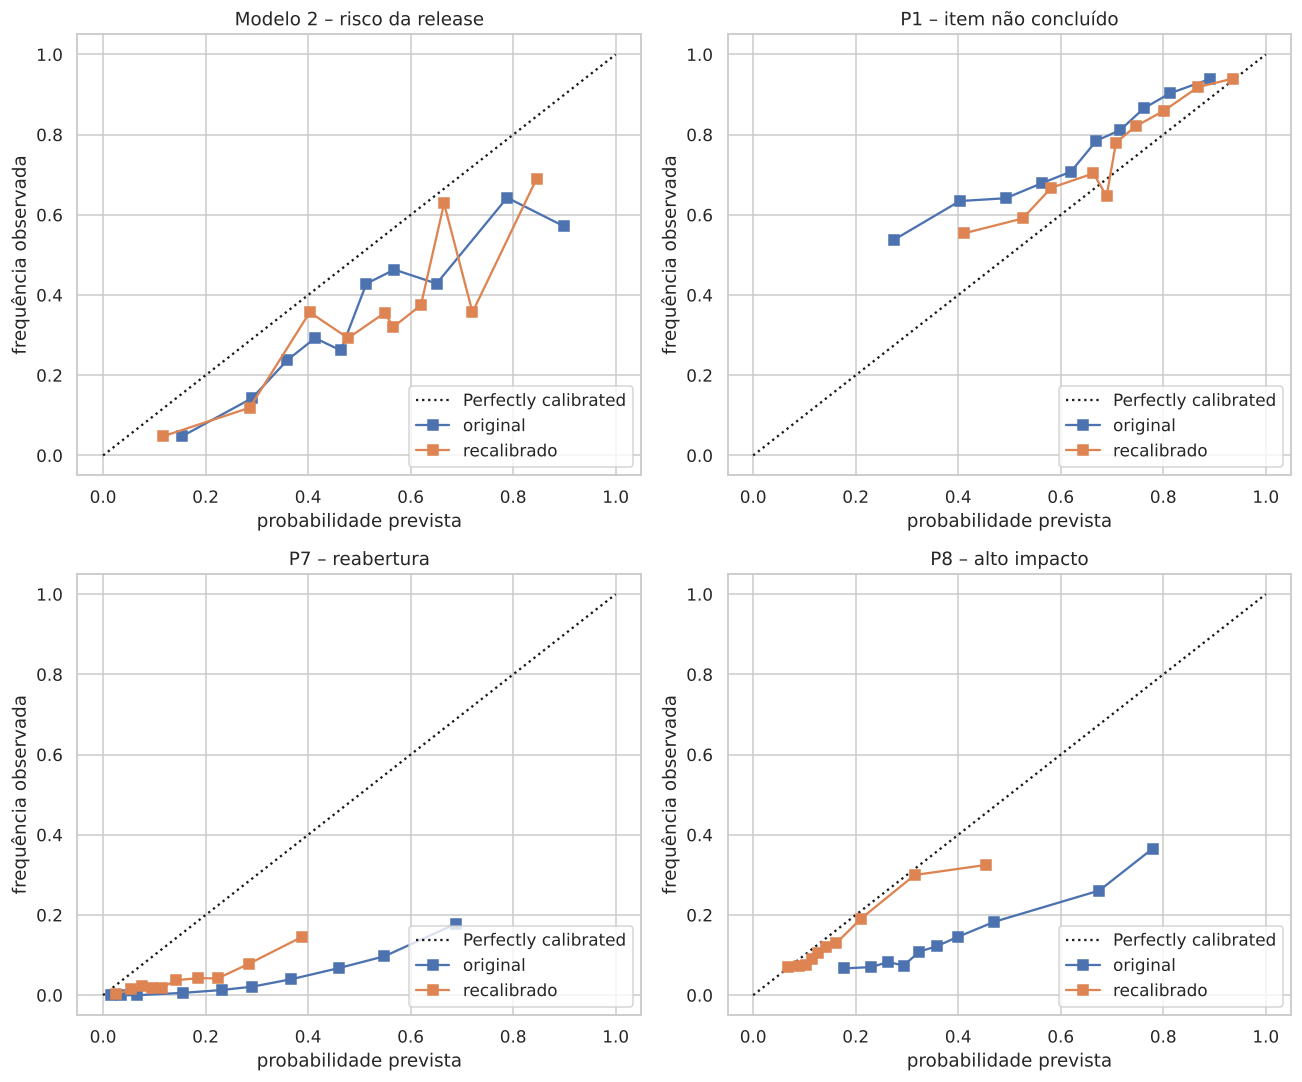

,modelo,Brier original,Brier recalibrado,AUC original,AUC recalibrado
0,Modelo 2 – risco da release,0.228,0.232,0.715,0.701
1,P1 – item não concluído,0.193,0.176,0.693,0.694
2,P7 – reabertura,0.125,0.057,0.842,0.743
3,P8 – alto impacto,0.188,0.120,0.691,0.685


In [39]:
from sklearn.calibration import CalibrationDisplay, CalibratedClassifierCV
from sklearn.base import clone
from sklearn.metrics import brier_score_loss

casos_bin = [
    ("Modelo 2 – risco da release", fit_r[melhor_r], tr_r.sort_values("Release_Date"), te_r, CAT_R + NUM_R, "Alto_Risco"),
    ("P1 – item não concluído", fit_s[melhor_s], tr_s.sort_values("Start_Date"), te_s, CAT_S + NUM_S, "Nao_Concluiu_No_Sprint"),
    ("P7 – reabertura", fit_re[melhor_re], tr_b, te_b, CAT_B + NUM_RE, "Foi_Reaberto"),
    ("P8 – alto impacto", fit_im[melhor_im], tr_b, te_b, CAT_B + NUM_B, "Alto_Impacto"),
]
fig, axs = plt.subplots(2, 2, figsize=(12, 10))
linhas = []
for (nome, modelo, tr_, te_, cols, alvo), ax in zip(casos_bin, axs.ravel()):
    cal = CalibratedClassifierCV(clone(modelo), method="isotonic", cv=TimeSeriesSplit(n_splits=3)).fit(tr_[cols], tr_[alvo])
    p_orig = modelo.predict_proba(te_[cols])[:, 1]
    p_cal = cal.predict_proba(te_[cols])[:, 1]
    CalibrationDisplay.from_predictions(te_[alvo], p_orig, n_bins=10, strategy="quantile", ax=ax, name="original")
    CalibrationDisplay.from_predictions(te_[alvo], p_cal, n_bins=10, strategy="quantile", ax=ax, name="recalibrado")
    ax.set(title=nome, xlabel="probabilidade prevista", ylabel="frequência observada")
    linhas.append((nome, brier_score_loss(te_[alvo], p_orig), brier_score_loss(te_[alvo], p_cal),
                   roc_auc_score(te_[alvo], p_orig), roc_auc_score(te_[alvo], p_cal)))
salvar("19_calibracao")
pd.DataFrame(linhas, columns=["modelo", "Brier original", "Brier recalibrado", "AUC original", "AUC recalibrado"]).round(3)

# 8. Conclusões (resultados desta execução)

**H1: o tipo e a composição da release influenciam os bugs pós-release? Sim, com efeito moderado.**
- O tipo de release importa (Kruskal-Wallis p < 0,001), mas com efeito pequeno (ε² ≈ 0,04). Releases **major** têm a maior mediana de bugs pós-release (39), contra 20,5 nas minor, 15 nas patch e 7 nas pre-release. Elas também têm a maior fatia de bugs de **prioridade alta** (≈ 27%, contra ≈ 14% nas minor), que é a proxy de impacto em cliente.
- Proporcionalmente, as **patch** geram mais bugs **por item entregue** (mediana 0,46, contra 0,23 nas minor; p < 0,001). Correções pequenas também introduzem defeitos.
- A Binomial Negativa controla tamanho e projeto. Nela, o que mais eleva a taxa de bugs é entregar **itens de prioridade alta** (RR ≈ 3,4 de 0% para 100% dos itens), o **tamanho** da release (RR ≈ 1,27 por unidade de log de itens), o número de **componentes tocados** (RR ≈ 1,24) e um **intervalo maior desde a release anterior** (RR ≈ 1,13). Já o **% de features não é significativo** (RR ≈ 0,99 a cada 10 p.p.; p = 0,65). Pesa mais *quanto e onde* se mexe do que *se é feature ou correção*.
- **Modelo 2:** Random Forest com AUC ≈ 0,72 e F1 macro ≈ 0,65 (baseline 0,50 e 0,26). Captura cerca de 69% das releases de alto risco. A regressão logística chega perto (AUC ≈ 0,71), o que mostra um sinal estável entre modelos. As variáveis mais importantes são componentes tocados, quantidade de itens, tipo de release, quantidade de correções e itens de prioridade alta.

**H2: dá para prever, na abertura, a faixa de tempo de correção? Parcialmente.**
- Bugs que afetam releases **patch** demoram mais (mediana ≈ 21 dias, contra ≈ 13 nas minor e ≈ 7 nas major; p < 0,001). A proporção de bugs com mais de 60 dias sobe de 22% (major) para 32% (patch).
- **Modelo 1:** Random Forest e XGBoost têm F1 macro ≈ 0,45 e acurácia balanceada ≈ 0,46 (baseline 0,19 e 0,33). A validação temporal confirma (XGBoost 0,43 ± 0,03). O ganho sobre o baseline é claro, mas o problema é difícil, como costuma ser na literatura de *bug fix time prediction*. O modelo acerta bem os bugs rápidos (recall ≈ 0,64) e tem mais dificuldade nos longos.
- Pelo SHAP, os fatores que mais pesam são a carga do time (bugs abertos no projeto), a experiência de quem reportou, quantas versões o bug afeta, o tempo desde a release afetada e o projeto.

**Perguntas complementares (seção 6)**
- **P1, previsto × realizado nos sprints:** em 970 sprints de 8 projetos, a mediana é de **apenas 42% do planejado concluído no próprio sprint**. Nos itens que estão no sprint no fechamento, ≈ 40% escorregam para o seguinte, e entra durante o sprint um escopo equivalente a ≈ 44% do planejado. O cumprimento varia de ≈ 20% (FAB) a ≈ 83% (NEXUS). Compromissos grandes (quartil superior de itens planejados) e sprints com mais pessoas cumprem menos (rho ≈ −0,18 e −0,22). A velocity é pouco previsível: usar a média dos 3 sprints anteriores erra ≈ 57% na mediana. No nível do item, o modelo que roda no início do sprint atinge AUC ≈ 0,69 (Regressão Logística). O sinal mais forte é o item **já ter passado por sprints anteriores**: o que escorrega uma vez tende a escorregar de novo.
- **P3, capacidade:** em média **≈ 53% da capacidade foi para sustentação** (correção de bugs). A fatia cai ao longo dos anos, de ≈ 74% em 2006 para ≈ 40% em 2019–2020, e varia muito entre projetos (de ≈ 26% a ≈ 69%). Picos de bugs **não deslocam** capacidade de forma relevante nos meses seguintes (rho ≈ 0,05 em t+1, n.s.). Entre releases, o efeito também é fraco (rho ≈ 0,08): muitos bugs em R levam a um pouco mais de correção em R+1, sem reduzir a fatia de features.
- **P5, pessoa-chave e sobrecarga:** em 3 dos 10 projetos (JAVA, DNN, TISTUD), **2 ou 3 pessoas resolvem metade dos bugs**, e no JAVA uma só pessoa concentra ≈ 48%. Os responsáveis mais centrais corrigem **mais rápido** (mediana ≈ 8 dias contra ≈ 17 dos menos centrais), o que mostra o *trade-off* entre eficiência e risco de dependência. A sobrecarga **aumenta o retrabalho**: os bugs reabertos sobem de ≈ 8% (carga baixa) para ≈ 14–16% (carga alta; qui-quadrado p < 0,001). O efeito da carga sobre o prazo não é consistente entre projetos.
- **P7, retrabalho:** no fechamento do bug, o Random Forest atinge AUC ≈ 0,84 e precisão média ≈ 0,17, contra uma taxa base de ≈ 0,04 (≈ 4× o acaso). O projeto (fluxo de cada time) e o tempo que levou para corrigir são os fatores dominantes, seguidos da carga do responsável.
- **P8, impacto em cliente:** ≈ 16% dos bugs viram "alto impacto" (duplicatas ou escalada de prioridade) e levam mais que o dobro do tempo (mediana ≈ 23 dias contra ≈ 10). Na abertura, o modelo atinge AUC ≈ 0,69 e precisão média ≈ 0,29, contra uma base de ≈ 0,15 (≈ 2× o acaso). O que mais pesa é o tamanho do backlog do projeto, o tamanho da descrição e a composição da release afetada.

**Robustez das escolhas (seção 7)**
- **Binomial Negativa × Poisson:** a variância dos bugs pós-release (≈ 4.161) é mais de 100 vezes a média (≈ 37), e a dispersão de Pearson da Poisson é ≈ 35, quando o adequado seria ≈ 1. O AIC da Binomial Negativa é bem menor (≈ 10,5 mil contra ≈ 38,4 mil). A escolha da Binomial Negativa está justificada.
- **Análise de sobrevivência:** só 53% dos bugs do período foram corrigidos (35% foram encerrados sem correção e 12% seguiam abertos). Olhar só os corrigidos subestima o tempo: a mediana passa de ≈ 12 dias para ≈ 23 dias quando os bugs abertos entram como censurados (e para ≈ 131 dias se os encerrados sem correção também forem tratados como censurados). Em **todos os cenários**, bugs de releases **patch** são os que mais demoram, seguidos dos de releases **minor**; major, pre-release e bugs sem versão são os mais rápidos. A conclusão sobre o tempo de correção (H2) é robusta à forma de tratar os bugs não corrigidos. Na regressão de Cox, prioridade maior acelera a correção (HR ≈ 1,32 por nível) e releases patch a retardam (HR ≈ 0,85 em relação a minor), com índice C ≈ 0,61 no teste.
- **Ajuste de hiperparâmetros:** a busca com validação temporal mudou as métricas de teste em no máximo ±0,015. As configurações fixas já estavam adequadas, e o limite de desempenho vem dos dados, não da escolha dos parâmetros.
- **Bootstrap:** no Modelo 1, na reabertura e no alto impacto, o melhor modelo supera a regressão logística com intervalo de confiança que não inclui zero. No Modelo 2, **Random Forest e regressão logística são estatisticamente equivalentes**, e no P1 a própria regressão logística é o melhor modelo; nesses casos, a regressão logística é preferível por ser mais simples e interpretável.
- **Calibração:** a ponderação de classes distorce as probabilidades. A recalibração (isotônica) reduz bastante o erro de Brier na reabertura (de 0,125 para 0,057) e no alto impacto (de 0,188 para 0,120). Para usar o modelo como "probabilidade de risco", é preciso recalibrar; para apenas ordenar os itens por risco, o modelo original basta.

**Aplicação em gestão de projetos.** Antes de publicar, o PMO pode usar o Modelo 2 como *checklist* de risco: releases que tocam muitos componentes ou carregam muitos itens críticos pedem mais homologação. Na triagem, o Modelo 1 ajuda a alocar capacidade e a comunicar prazo ao cliente.

# 9. Limitações
1. **Dados open source**, não corporativos. A dinâmica de prazo e prioridade pode diferir de uma empresa com SLA.
2. **Horas apontadas** (`Timespent`) existem em cerca de 3% dos bugs. Por isso o tempo usado é o de calendário (abertura → resolução), não o esforço.
3. **Impacto em cliente** é aproximado pela prioridade dos bugs pós-release. Não há campo de cliente afetado.
4. **Atribuição de bugs a releases** depende do preenchimento de *affected version* pelos times. Cerca de 30% dos bugs não têm versão afetada.
5. Componentes e versões afetadas refletem o estado final da issue, não necessariamente o do dia da abertura. A prioridade foi reconstruída para o valor inicial a partir do histórico de mudanças.
6. `Alto_Risco` usa a mediana do projeto em todo o período, um vazamento leve aceitável para fins comparativos. Alternativa: usar a mediana só do período de treino.
7. **Responsável** é o atribuído no estado final da issue, não necessariamente quem estava com o bug no dia da abertura.
8. **Reabertura** depende do fluxo de cada time: alguns projetos quase não usam o status *Reopened*. Por isso o projeto é a variável que mais pesa no P7. A taxa também cai muito depois de 2016 (de ≈ 14,5% para ≈ 4,2%), o que exige cautela ao generalizar esse modelo.
9. **Capacidade** é medida em quantidade de itens resolvidos, não em horas, porque as horas apontadas são escassas.
10. **Encerramentos sem correção** ("Won't Fix", "Duplicate" etc.) são um risco concorrente: na análise de sobrevivência foram tratados como censura e, em sensibilidade, excluídos. Uma análise de riscos competitivos seria o refinamento seguinte.
11. **Sprints:** "concluído" significa resolvido até 1 dia após o fechamento do sprint, pela data de resolução final; um item reaberto depois conta como não concluído. Os story points são os do estado final. SERVER e DNN ficaram de fora por não terem as datas dos sprints na base. A taxa de itens que escorregam é maior no período de teste (≈ 75%) do que no histórico.